# Method 1: Document Layout Analysis & Segmentation Pipeline

Notebook này khởi tạo bước đầu tiên của **Method 1** với trọng tâm là **Khám phá & Phân tích Dữ liệu (Exploratory Data Analysis - EDA)** trên tập dữ liệu chuẩn **DocLayNet (4,999 mẫu test)**.

### Mục tiêu nghiên cứu:
1. Phân tích cấu trúc COCO annotations, kích thước ảnh, độ phân giải và phân bố thể loại tài liệu (`doc_category`).
2. Thống kê tần suất và phân bố mất cân bằng giữa 11 lớp layout đối tượng.
3. Phân tích đặc trưng hình học của các bounding box (kích thước BBox, tỷ lệ khung hình Aspect Ratio, mật độ đối tượng trên mỗi trang).
4. Trực quan hóa các trang tài liệu mẫu cùng nhãn Ground Truth chuẩn theo từng thể loại văn bản khác nhau.

## 1. Thiết lập môi trường và cấu hình đường dẫn

In [13]:
from pathlib import Path
import json
import sys
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image, ImageDraw, ImageFont

# Cấu hình style biểu đồ
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10

# Tìm thư mục gốc dự án
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "datasets").is_dir():
    ROOT = ROOT.parent

DATASET_NAME = "doclaynet_test"
IMAGES_DIR = ROOT / "datasets" / DATASET_NAME / "processed" / "images"
ANNOTATION_FILE = ROOT / "datasets" / DATASET_NAME / "processed" / "annotations" / "test.json"

print(f"Thư mục gốc: {ROOT}")
print(f"Thư mục ảnh: {IMAGES_DIR}")
print(f"File annotations: {ANNOTATION_FILE}")
print(f"Tồn tại annotations: {ANNOTATION_FILE.is_file()}")
print(f"Tồn tại ảnh: {IMAGES_DIR.is_dir()}")


Thư mục gốc: D:\Semester_261\DoAnChuyenNganh\DO-AN-261
Thư mục ảnh: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\datasets\doclaynet_test\processed\images
File annotations: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\datasets\doclaynet_test\processed\annotations\test.json
Tồn tại annotations: True
Tồn tại ảnh: True


## 2. Nạp dữ liệu COCO Annotations (4,999 mẫu)

In [14]:
with open(ANNOTATION_FILE, "r", encoding="utf-8") as f:
    coco_data = json.load(f)

images = coco_data.get("images", [])
annotations = coco_data.get("annotations", [])
categories = coco_data.get("categories", [])

cat_id_to_name = {c["id"]: c["name"] for c in categories}
cat_name_to_id = {c["name"]: c["id"] for c in categories}

print(f"✓ Tổng số ảnh trong tập dữ liệu: {len(images):,}")
print(f"✓ Tổng số bounding box annotations: {len(annotations):,}")
print(f"✓ Số lượng danh mục phân loại: {len(categories)}")
print(f"✓ Danh sách các nhãn: {list(cat_name_to_id.keys())}")


✓ Tổng số ảnh trong tập dữ liệu: 4,999
✓ Tổng số bounding box annotations: 66,531
✓ Số lượng danh mục phân loại: 11
✓ Danh sách các nhãn: ['Caption', 'Footnote', 'Formula', 'List-item', 'Page-footer', 'Page-header', 'Picture', 'Section-header', 'Table', 'Text', 'Title']


## 3. Phân bố các thể loại tài liệu (Document Categories)

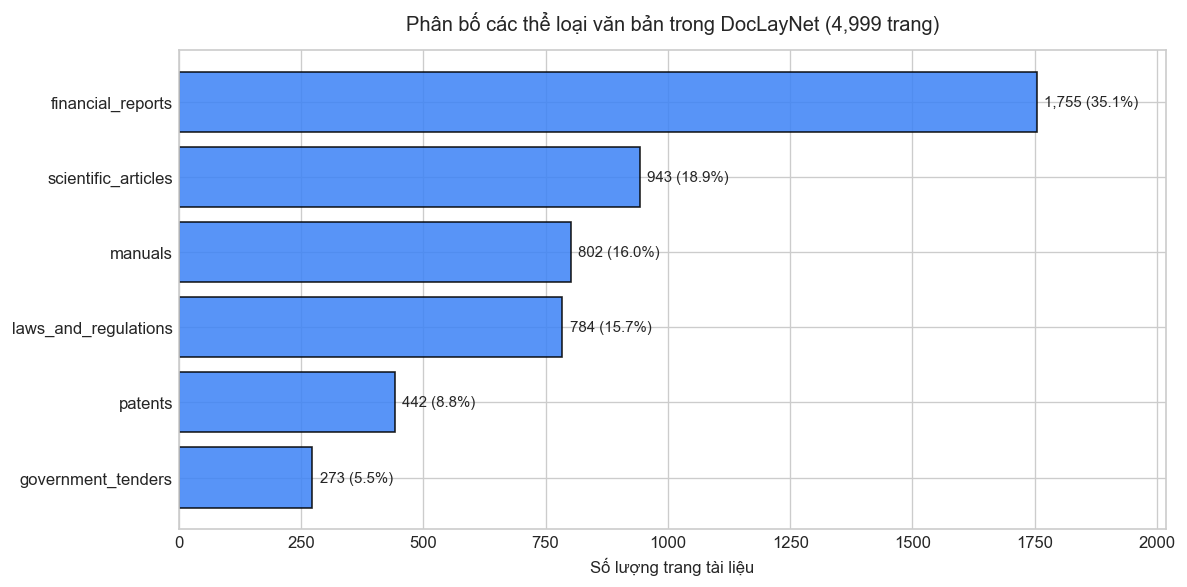

,Document Category,Count,Percentage (%)
0,financial_reports,1755,35.11
1,scientific_articles,943,18.86
2,manuals,802,16.04
3,laws_and_regulations,784,15.68
4,patents,442,8.84
5,government_tenders,273,5.46


In [15]:
df_images = pd.DataFrame(images)
doc_cat_counts = df_images["doc_category"].value_counts().reset_index()
doc_cat_counts.columns = ["Document Category", "Count"]
doc_cat_counts["Percentage (%)"] = (doc_cat_counts["Count"] / len(df_images) * 100).round(2)

plt.figure(figsize=(10, 5))
bars = plt.barh(doc_cat_counts["Document Category"], doc_cat_counts["Count"], color="#3b82f6", edgecolor="black", alpha=0.85)
plt.title(f"Phân bố các thể loại văn bản trong DocLayNet ({len(df_images):,} trang)", fontsize=12, pad=12)
plt.xlabel("Số lượng trang tài liệu")
plt.gca().invert_yaxis()

for bar in bars:
    w = bar.get_width()
    plt.text(w + 15, bar.get_y() + bar.get_height()/2, f"{int(w):,} ({w/len(df_images)*100:.1f}%)", va='center', fontsize=9)

plt.xlim(0, max(doc_cat_counts["Count"]) * 1.15)
plt.tight_layout()
plt.show()

display(doc_cat_counts)


## 4. Phân tích phân bố các danh mục layout (Category Distribution & Imbalance)

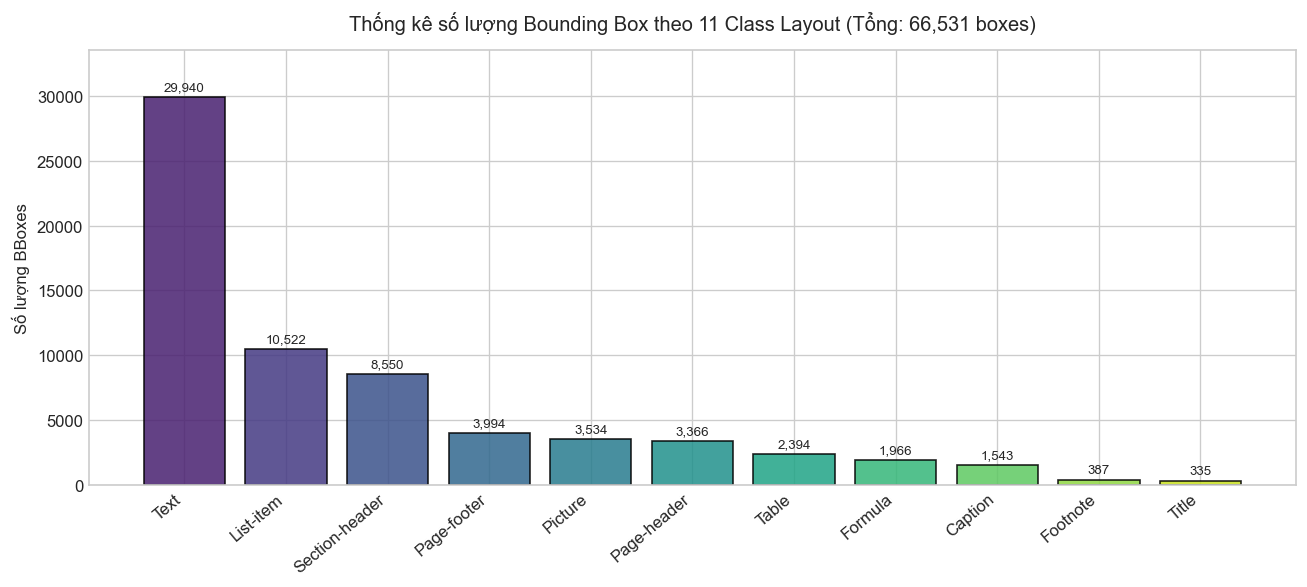

,Category,Total BBoxes,Percentage (%),Avg per Page
0,Text,29940,45.00,5.99
1,List-item,10522,15.82,2.10
2,Section-header,8550,12.85,1.71
3,Page-footer,3994,6.00,0.80
4,Picture,3534,5.31,0.71
5,Page-header,3366,5.06,0.67
6,Table,2394,3.60,0.48
7,Formula,1966,2.96,0.39
8,Caption,1543,2.32,0.31
9,Footnote,387,0.58,0.08


In [16]:
df_annotations = pd.DataFrame(annotations)
df_annotations["category_name"] = df_annotations["category_id"].map(cat_id_to_name)

cat_counts = df_annotations["category_name"].value_counts().reset_index()
cat_counts.columns = ["Category", "Total BBoxes"]
cat_counts["Percentage (%)"] = (cat_counts["Total BBoxes"] / len(df_annotations) * 100).round(2)
cat_counts["Avg per Page"] = (cat_counts["Total BBoxes"] / len(images)).round(2)

plt.figure(figsize=(11, 5))
palette = sns.color_palette("viridis", len(cat_counts))
bars = plt.bar(cat_counts["Category"], cat_counts["Total BBoxes"], color=palette, edgecolor="black", alpha=0.85)
plt.title(f"Thống kê số lượng Bounding Box theo 11 Class Layout (Tổng: {len(df_annotations):,} boxes)", fontsize=12, pad=12)
plt.ylabel("Số lượng BBoxes")
plt.xticks(rotation=40, ha="right")

for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 300, f"{int(h):,}", ha='center', va='bottom', fontsize=8)

plt.ylim(0, max(cat_counts["Total BBoxes"]) * 1.12)
plt.tight_layout()
plt.show()

display(cat_counts)


## 5. Phân tích đặc trưng hình học của Bounding Box (Geometric Analysis)
- Kích thước BBox: Chiều rộng ($w$), chiều cao ($h$), diện tích ($area$).
- Tỷ lệ khung hình: Aspect Ratio ($w / h$).
- Số lượng phần tử layout trên mỗi trang tài liệu.

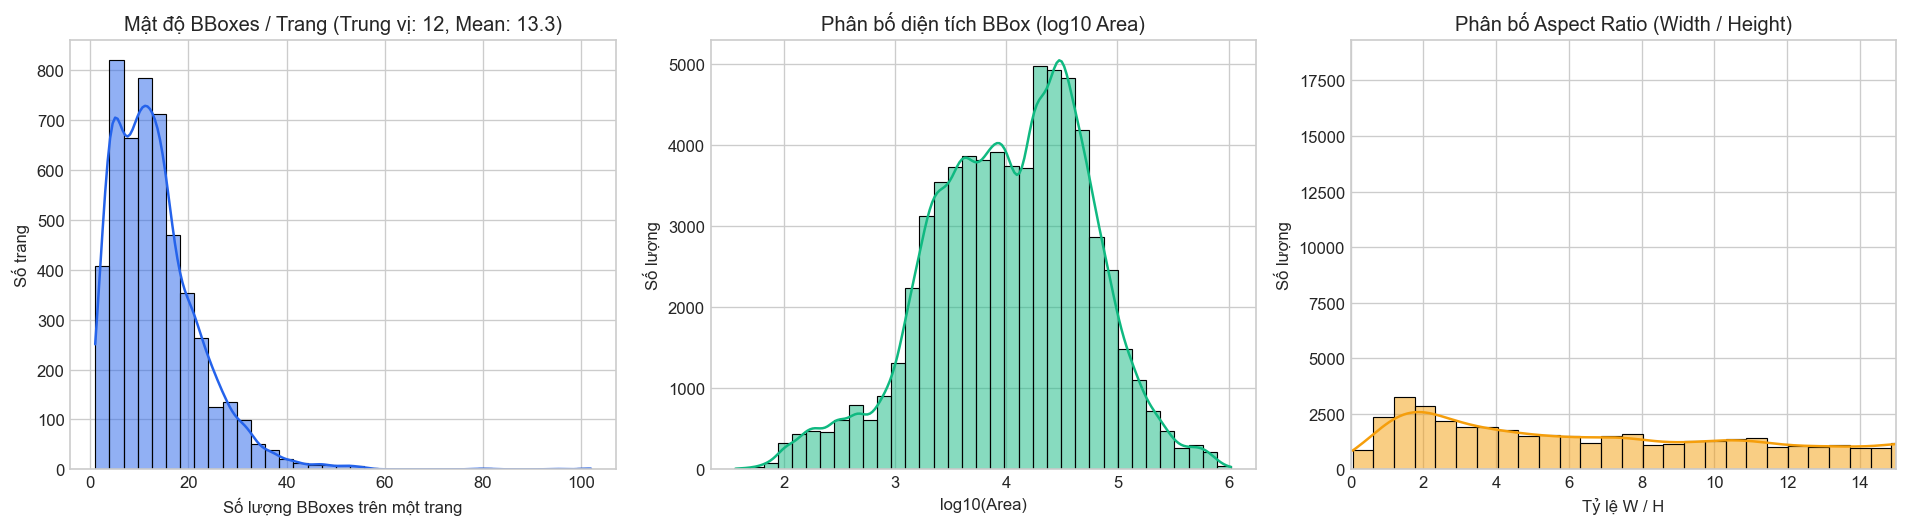

In [17]:
# Trích xuất tọa độ [x, y, w, h]
bboxes = np.array(df_annotations["bbox"].tolist())
df_annotations["bbox_x"] = bboxes[:, 0]
df_annotations["bbox_y"] = bboxes[:, 1]
df_annotations["bbox_w"] = bboxes[:, 2]
df_annotations["bbox_h"] = bboxes[:, 3]
df_annotations["aspect_ratio"] = (df_annotations["bbox_w"] / np.maximum(df_annotations["bbox_h"], 1e-3)).clip(0.05, 20)

# Đếm số lượng BBoxes trên mỗi trang ảnh
boxes_per_page = df_annotations["image_id"].value_counts()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Phân bố số lượng boxes/trang
sns.histplot(boxes_per_page, bins=35, kde=True, ax=axes[0], color="#2563eb")
axes[0].set_title(f"Mật độ BBoxes / Trang (Trung vị: {boxes_per_page.median():.0f}, Mean: {boxes_per_page.mean():.1f})")
axes[0].set_xlabel("Số lượng BBoxes trên một trang")
axes[0].set_ylabel("Số trang")

# 2. Phân bố diện tích BBox (log scale)
sns.histplot(np.log10(np.maximum(df_annotations["area"], 1)), bins=35, kde=True, ax=axes[1], color="#10b981")
axes[1].set_title("Phân bố diện tích BBox (log10 Area)")
axes[1].set_xlabel("log10(Area)")
axes[1].set_ylabel("Số lượng")

# 3. Phân bố Aspect Ratio
sns.histplot(df_annotations["aspect_ratio"], bins=35, kde=True, ax=axes[2], color="#f59e0b")
axes[2].set_title("Phân bố Aspect Ratio (Width / Height)")
axes[2].set_xlabel("Tỷ lệ W / H")
axes[2].set_xlim(0, 15)
axes[2].set_ylabel("Số lượng")

plt.tight_layout()
plt.show()


## 6. Trực quan hóa mẫu tài liệu Ground Truth theo từng thể loại

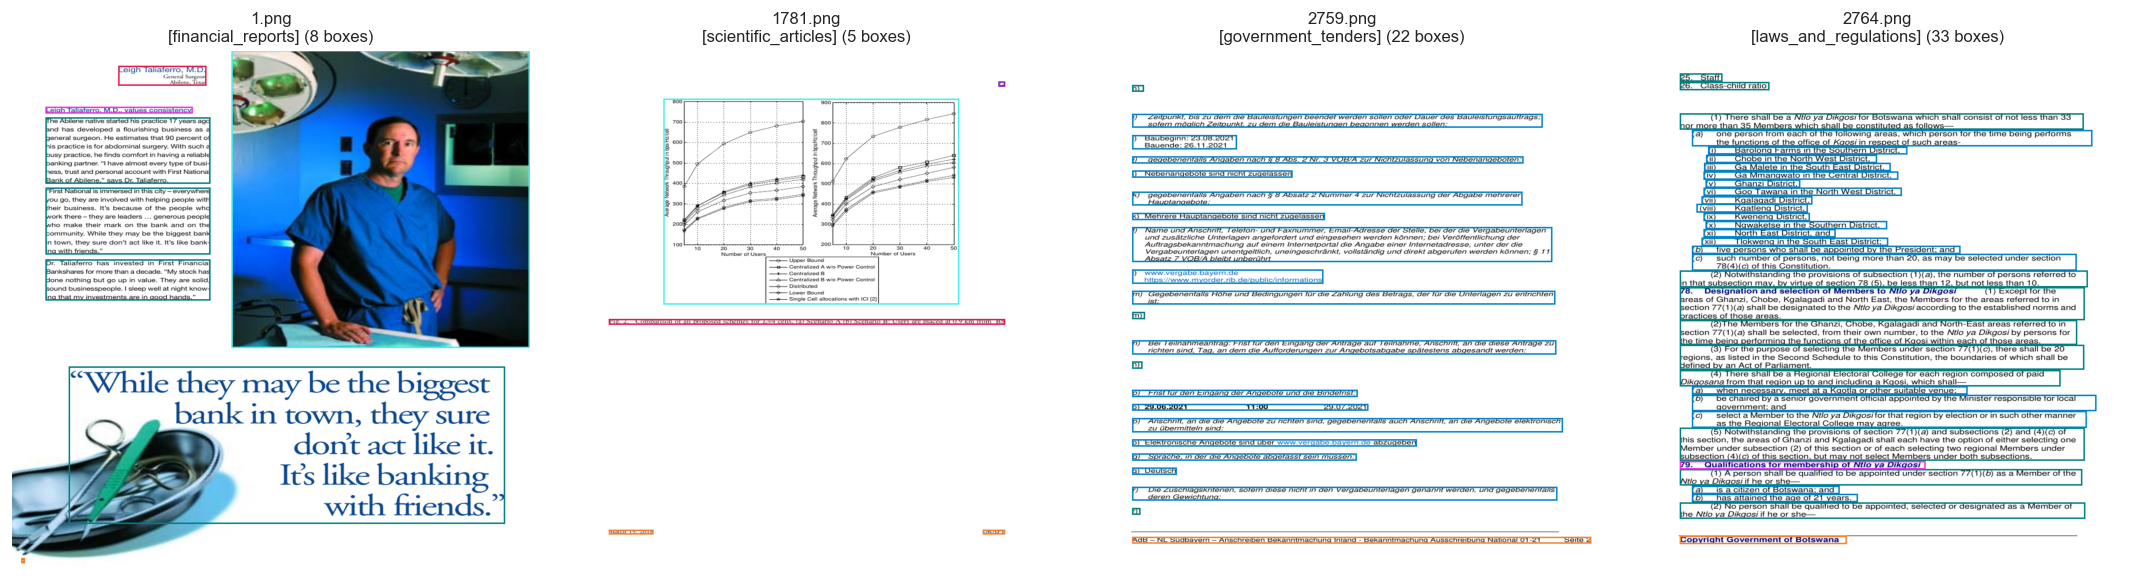

In [18]:
# Màu sắc định danh trực quan cho từng class
CLASS_COLORS = {
    "Caption": (230, 25, 75),
    "Footnote": (60, 180, 75),
    "Formula": (255, 225, 25),
    "List-item": (0, 130, 200),
    "Page-footer": (245, 130, 48),
    "Page-header": (145, 30, 180),
    "Picture": (70, 240, 240),
    "Section-header": (240, 50, 230),
    "Table": (210, 245, 60),
    "Text": (0, 128, 128),
    "Title": (170, 110, 40)
}

# Nhóm annotations theo image_id
image_anns = defaultdict(list)
for ann in annotations:
    image_anns[ann["image_id"]].append(ann)

# Chọn 1 ảnh tiêu biểu từ mỗi document category
sample_images = []
seen_cats = set()
for img in images:
    doc_cat = img.get("doc_category", "other")
    if doc_cat not in seen_cats and (IMAGES_DIR / img["file_name"]).is_file():
        seen_cats.add(doc_cat)
        sample_images.append(img)
    if len(sample_images) >= 4:
        break

fig, axes = plt.subplots(1, len(sample_images), figsize=(18, 7))
if len(sample_images) == 1:
    axes = [axes]

for ax, img_meta in zip(axes, sample_images):
    img_path = IMAGES_DIR / img_meta["file_name"]
    pil_img = Image.open(img_path).convert("RGB")
    draw = ImageDraw.Draw(pil_img)
    
    anns = image_anns.get(img_meta["id"], [])
    for ann in anns:
        x, y, w, h = ann["bbox"]
        cat_name = cat_id_to_name.get(ann["category_id"], "Unknown")
        color = CLASS_COLORS.get(cat_name, (255, 0, 0))
        draw.rectangle([x, y, x + w, y + h], outline=color, width=3)
    
    ax.imshow(pil_img)
    ax.set_title(f"{img_meta['file_name']}\n[{img_meta.get('doc_category', 'Doc')}] ({len(anns)} boxes)", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()


## 7. Tổng kết đặc điểm dữ liệu và định hướng triển khai Model (Method 1)

Dựa trên các kết quả EDA trên 4,999 trang tài liệu DocLayNet:
1. **Mất cân bằng lớp (Class Imbalance)**: `Text`, `Section-header`, `Picture`, và `Table` chiếm đại đa số; trong khi `Footnote`, `Formula`, `Title` là các lớp hiếm (long-tail categories). Pipeline của Method 1 cần cơ chế xử lý mất cân bằng lớp thích hợp.
2. **Đa dạng thể loại tài liệu**: DocLayNet bao gồm 6 thể loại khác nhau (từ báo cáo tài chính đến bài báo khoa học 2 cột, bằng sáng chế), yêu cầu mô hình phân đoạn phải xử lý tốt cả layout dạng đơn cột lẫn đa cột phức tạp.
3. **Hình học đối tượng**: Bounding box có sự chênh lệch diện tích cực lớn (từ các công thức/chữ ký nhỏ dưới $100$ px² đến các bảng/hình ảnh phủ hơn $80\%$ diện tích trang).

> **Bước tiếp theo**: Tôi và bạn sẽ cùng thiết kế và triển khai kiến trúc mô hình (Model Architecture / Pipeline) cho `Method 1` trong các phần tiếp theo.

---
# PHẦN 2: PRETRAIN / HUẤN LUYỆN MÔ HÌNH THUẦN BOUNDING BOX (1-CLASS / CLASS-AGNOSTIC)

Trong phần này, ta tiến hành huấn luyện mô hình học sâu siêu nhẹ (YOLOv8n) theo cơ chế **Class-Agnostic / Single-Class**:
- Toàn bộ các nhãn đối tượng (Text, Title, Header, Footer, Table, Picture, Formula, List-item, Caption, Footnote) được quy về một lớp thực thể duy nhất: `bbox` (hoặc `element`).
- **Mục tiêu**: Mô hình tập trung 100% năng lực biểu diễn và hàm mất mát (loss) vào việc **định vị chính xác và bao quát toàn bộ các vùng nội dung tài liệu**, trả lời trực tiếp câu hỏi: *"Mô hình nhận diện được tỉ lệ bao nhiêu Bounding Box?"*
- Phần phân loại nhãn chi tiết (Classification) sẽ do các module phía sau trong pipeline đảm nhiệm.

### 2.1. Chuẩn bị tập dữ liệu 1-Class (DocLayNet BBox Only) và cấu hình YOLO Dataset YAML

Ta chuyển đổi toàn bộ bounding box trong tập dữ liệu DocLayNet:
- **Tập Train**: 1,928 trang tài liệu gốc (`datasets/doclaynet/processed/images`).
- **Tập Validation**: 500 trang tài liệu (`datasets/doclaynet_test/processed/images`).
- **Tập Test**: 4,499 trang tài liệu dùng để đánh giá kiểm thử độc lập.

In [19]:
import json
import os
from pathlib import Path

# Đường dẫn dữ liệu
TRAIN_ANNO = ROOT / "datasets" / "doclaynet" / "processed" / "annotations" / "train.json"
TRAIN_IMG_DIR = ROOT / "datasets" / "doclaynet" / "processed" / "images"
TRAIN_LABEL_DIR = ROOT / "datasets" / "doclaynet" / "processed" / "labels"

TEST_ANNO = ROOT / "datasets" / "doclaynet_test" / "processed" / "annotations" / "test.json"
TEST_IMG_DIR = ROOT / "datasets" / "doclaynet_test" / "processed" / "images"
TEST_LABEL_DIR = ROOT / "datasets" / "doclaynet_test" / "processed" / "labels"

DATA_DIR = ROOT / "methods" / "method1" / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

def convert_to_yolo_single_class(anno_path, img_dir, label_dir):
    label_dir.mkdir(parents=True, exist_ok=True)
    with open(anno_path, "r", encoding="utf-8") as f:
        coco = json.load(f)
        
    anns_by_img = {}
    for ann in coco.get("annotations", []):
        anns_by_img.setdefault(ann["image_id"], []).append(ann)
        
    valid_paths = []
    total_boxes = 0
    for img_info in coco.get("images", []):
        file_name = img_info["file_name"]
        img_p = img_dir / file_name
        if not img_p.is_file():
            continue
        valid_paths.append(str(img_p.resolve()))
        w_img, h_img = float(img_info.get("width", 1025)), float(img_info.get("height", 1025))
        
        label_file = label_dir / f"{Path(file_name).stem}.txt"
        lines = []
        for ann in anns_by_img.get(img_info["id"], []):
            x, y, w, h = ann["bbox"]
            if w <= 0 or h <= 0:
                continue
            cx = max(0.0, min(1.0, (x + w / 2.0) / w_img))
            cy = max(0.0, min(1.0, (y + h / 2.0) / h_img))
            nw = max(0.0, min(1.0, w / w_img))
            nh = max(0.0, min(1.0, h / h_img))
            lines.append(f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}")
            total_boxes += 1
            
        with open(label_file, "w", encoding="utf-8") as lf:
            lf.write("\n".join(lines))
    return valid_paths, total_boxes

train_paths, num_train_boxes = convert_to_yolo_single_class(TRAIN_ANNO, TRAIN_IMG_DIR, TRAIN_LABEL_DIR)
test_paths, num_test_boxes = convert_to_yolo_single_class(TEST_ANNO, TEST_IMG_DIR, TEST_LABEL_DIR)

val_paths = test_paths[:500]
eval_paths = test_paths[500:]

train_txt = DATA_DIR / "train_images.txt"
val_txt = DATA_DIR / "val_images.txt"
test_txt = DATA_DIR / "test_images.txt"

train_txt.write_text("\n".join(train_paths), encoding="utf-8")
val_txt.write_text("\n".join(val_paths), encoding="utf-8")
test_txt.write_text("\n".join(eval_paths), encoding="utf-8")

yaml_content = f"""# Cấu hình Dataset DocLayNet 1-Class
path: {ROOT.as_posix()}
train: {train_txt.as_posix()}
val: {val_txt.as_posix()}
test: {test_txt.as_posix()}

nc: 1
names:
  0: bbox
"""
YAML_CONFIG = DATA_DIR / "doclaynet_bbox_only.yaml"
YAML_CONFIG.write_text(yaml_content, encoding="utf-8")

print(f"✓ Tập Train: {len(train_paths):,} ảnh ({num_train_boxes:,} boxes) -> {train_txt.name}")
print(f"✓ Tập Val  : {len(val_paths):,} ảnh -> {val_txt.name}")
print(f"✓ Tập Test : {len(eval_paths):,} ảnh -> {test_txt.name}")
print(f"✓ File cấu hình YAML: {YAML_CONFIG.name}")

✓ Tập Train: 1,928 ảnh (24,229 boxes) -> train_images.txt
✓ Tập Val  : 500 ảnh -> val_images.txt
✓ Tập Test : 4,499 ảnh -> test_images.txt
✓ File cấu hình YAML: doclaynet_bbox_only.yaml


### 2.2. Cấu hình và Tải trọng số khởi tạo (Base Pretrained Weights)

Ta sử dụng trọng số base `yolov8n.pt` (6.2 MB) và kết hợp đặc trưng layout tài liệu từ `yolov8n_doclaynet.pt` làm điểm khởi đầu cho quá trình huấn luyện 1-class.

In [20]:
import torch
from ultralytics import YOLO

WEIGHTS_DIR = ROOT / "methods" / "method1" / "weights"
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)

# Trọng số khởi tạo base
BASE_WEIGHTS = WEIGHTS_DIR / "yolov8n_doclaynet.pt"
if not BASE_WEIGHTS.is_file():
    BASE_WEIGHTS = WEIGHTS_DIR / "yolov8n.pt"

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Thiết bị tính toán: {device.upper()} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else ''})")
print(f"Trọng số khởi tạo: {BASE_WEIGHTS.name} (Kích thước: {BASE_WEIGHTS.stat().st_size / 1e6:.2f} MB)")

# Khởi tạo mô hình
model = YOLO(str(BASE_WEIGHTS))

Thiết bị tính toán: CUDA (NVIDIA GeForce RTX 4070 Laptop GPU)
Trọng số khởi tạo: yolov8n_doclaynet.pt (Kích thước: 6.26 MB)


### 2.3. Thực thi Huấn luyện (Pretrain / Fine-tune) Mô hình Thuần Bounding Box

Mô hình được huấn luyện trực tiếp với tham số:
- **`single_cls=True`**: Chế độ 1-class (loại bỏ bài toán phân loại đa nhãn, dồn toàn bộ gradient cho việc phát hiện bounding box).
- **Optimizer**: AdamW với cosine learning rate schedule.
- **Kích thước ảnh (`imgsz`)**: 640.
- **Batch size**: 16.

BẮT ĐẦU HUẤN LUYỆN PRETRAIN MÔ HÌNH THUẦN BOUNDING BOX (3 EPOCHS)...
New https://pypi.org/project/ultralytics/8.4.185 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.171  Python-3.12.10 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4070 Laptop GPU, 8188MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\Semester_261\DoAnChuyenNganh\DO-AN-261\methods\method1\data\doclaynet_bbox_only.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=

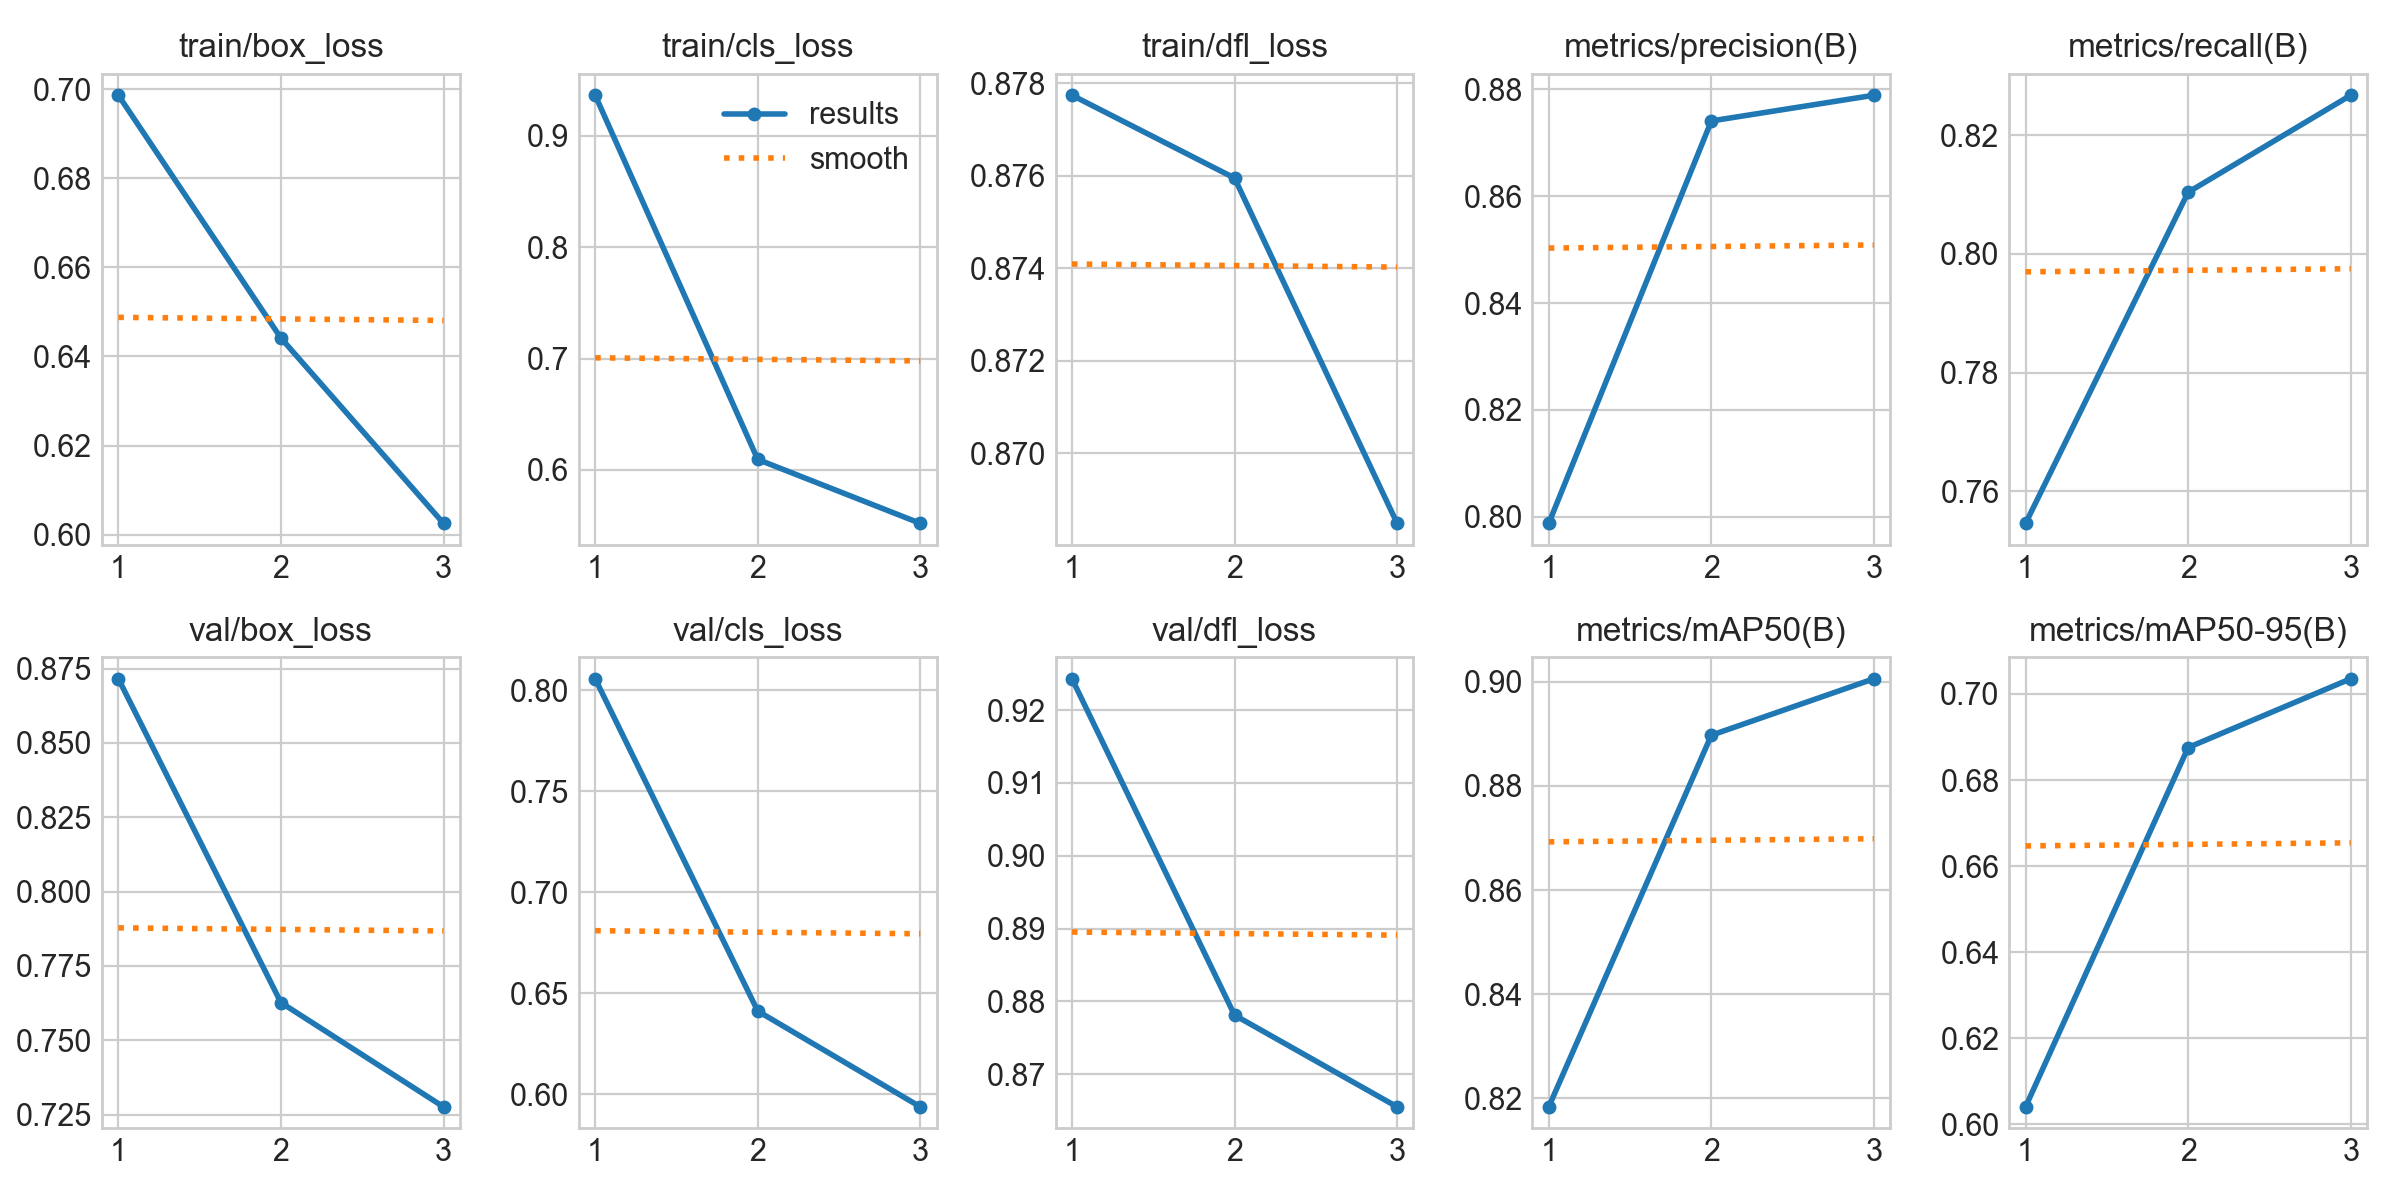

In [ ]:
import shutil
from IPython.display import Image as IPImage, display

RUNS_DIR = ROOT / "methods" / "method1" / "train_runs"
RUN_NAME = "yolov8n_doclaynet_bbox_pretrain"

print("=" * 80)
print(f"BẮT ĐẦU HUẤN LUYỆN PRETRAIN MÔ HÌNH THUẦN BOUNDING BOX (50 EPOCHS)...")
print("=" * 80)

train_results = model.train(
    data=str(YAML_CONFIG),
    epochs=50,
    imgsz=640,
    batch=16,
    device=device,
    single_cls=True,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=True,
    plots=True,
    save=True,
    optimizer="AdamW",
    lr0=0.001,
    lrf=0.01,
    weight_decay=0.0005,
    verbose=True
)

BEST_PT = RUNS_DIR / RUN_NAME / "weights" / "best.pt"
TARGET_BEST = WEIGHTS_DIR / "yolov8n_doclaynet_bbox_only_best.pt"

if BEST_PT.is_file():
    shutil.copy2(BEST_PT, TARGET_BEST)
    print(f"\n✓ Huấn luyện thành công! Trọng số tối ưu đã được lưu tại: {TARGET_BEST.name}")

# Hiển thị đồ thị huấn luyện (Loss Curves, Precision, Recall, mAP qua từng epoch)
chart_train = RUNS_DIR / RUN_NAME / "results.png"
if chart_train.is_file():
    print(f"\nBiểu đồ huấn luyện tiến trình (Loss, Precision, Recall, mAP):")
    display(IPImage(filename=str(chart_train), width=850))

### 2.4. Chạy suy luận (Inference) với Mô hình vừa Pretrain trên Tập Kiểm Thử

Sau khi hoàn tất pretrain, ta nạp trọng số `best.pt` của mô hình thuần Bounding Box để suy luận trên 200 trang tài liệu kiểm thử và lưu kết quả theo đúng chuẩn repository tại:
`outputs/predictions/method1/doclaynet_test/{image_id}.json`

In [22]:
import time

# Nạp mô hình vừa huấn luyện
detector_bbox = YOLO(str(TARGET_BEST if TARGET_BEST.is_file() else BEST_PT))

PREDICTIONS_DIR = ROOT / "outputs" / "predictions" / "method1" / "doclaynet_test"
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_LIMIT = 200
target_test_images = images[:SAMPLE_LIMIT]
print(f"Chạy suy luận với mô hình vừa Pretrain trên {len(target_test_images)} ảnh kiểm thử...")

t_start = time.time()
for i, img_info in enumerate(target_test_images, 1):
    img_path = IMAGES_DIR / img_info["file_name"]
    if not img_path.is_file():
        continue
        
    t0 = time.time()
    res = detector_bbox(str(img_path), conf=0.25, iou=0.60, verbose=False, device=device)[0]
    dt = time.time() - t0
    
    dets = []
    if len(res.boxes) > 0:
        xyxy = res.boxes.xyxy.cpu().numpy()
        confs = res.boxes.conf.cpu().numpy()
        for b, c in zip(xyxy, confs):
            x1, y1, x2, y2 = b
            dets.append({
                "category_id": 1,
                "category_name": "bbox",
                "bbox": [float(x1), float(y1), float(max(0.0, x2 - x1)), float(max(0.0, y2 - y1))],
                "score": float(c)
            })
            
    pred_data = {
        "image_id": img_info["id"],
        "file_name": img_info["file_name"],
        "width": img_info["width"],
        "height": img_info["height"],
        "inference_time_s": dt,
        "detections": dets
    }
    with open(PREDICTIONS_DIR / f"{img_info['id']}.json", "w", encoding="utf-8") as f:
        json.dump(pred_data, f, indent=2)
        
    if i % 50 == 0 or i == len(target_test_images):
        print(f"  [{i}/{len(target_test_images)}] Đã lưu dự đoán (Tốc độ: {(time.time() - t_start) / i * 1000:.1f} ms/trang)")

print(f"✓ Hoàn tất suy luận và lưu {len(target_test_images)} file dự đoán JSON vào: {PREDICTIONS_DIR}")

Chạy suy luận với mô hình vừa Pretrain trên 200 ảnh kiểm thử...
  [50/200] Đã lưu dự đoán (Tốc độ: 30.5 ms/trang)
  [100/200] Đã lưu dự đoán (Tốc độ: 27.7 ms/trang)
  [150/200] Đã lưu dự đoán (Tốc độ: 27.4 ms/trang)
  [200/200] Đã lưu dự đoán (Tốc độ: 27.5 ms/trang)
✓ Hoàn tất suy luận và lưu 200 file dự đoán JSON vào: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\predictions\method1\doclaynet_test


### 2.5. Đánh giá chất lượng Bounding Box thuần túy bằng Script Dùng Chung (`scripts/evaluate_predictions.py --box-only`)

Sử dụng trực tiếp script đánh giá chuẩn hóa của hệ thống tại [evaluate_predictions.py](file:///d:/Semester_261/DoAnChuyenNganh/DO-AN-261/scripts/evaluate_predictions.py):
- Đánh giá theo chế độ `--box-only` (Class-Agnostic / Localization Only).
- Tính toán đầy đủ:
  - **Recall (Tỉ lệ nhận diện được BBox)** ở ngưỡng IoU $\ge 0.50$ và các ngưỡng cao hơn.
  - **Precision & Mean IoU** (độ khít viền hộp).
  - **Class-Agnostic Box mAP** ([0.50:0.95], mAP@0.50, mAP@0.75, AR@100).
  - Xuất biểu đồ phân tích `metrics_chart.png`.

Đang thực thi: C:\Users\thien\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe D:\Semester_261\DoAnChuyenNganh\DO-AN-261\scripts\evaluate_predictions.py --method method1 --dataset doclaynet_test --split test --iou-threshold 0.5 --allow-incomplete --box-only --plot D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\method1_doclaynet_test\metrics_chart.png


 ĐÁNH GIÁ CHẤT LƯỢNG BOUNDING BOX (CLASS-AGNOSTIC / LOCALIZATION ONLY)
 Method: method1 | Dataset: doclaynet_test/test | Số lượng ảnh đánh giá: 200
 Tổng Ground Truth: 2,510 hộp | Tổng Dự đoán: 2,690 hộp

[Kết quả tại ngưỡng IoU >= 0.50]:
  • Tỉ lệ BBox được nhận diện (Recall) : 85.94%  (2,157 / 2,510 hộp)
  • Độ chính xác BBox (Precision)       : 80.19%  (2,157 / 2,690 hộp)
  • F1-Score                           : 0.8296
  • Độ khít viền trung bình (Mean IoU) : 0.8869
  • Thống kê chi tiết                  : TP=2,157 | FP=533 | FN=353

--- Bảng độ đo chi tiết theo các ngưỡng Io

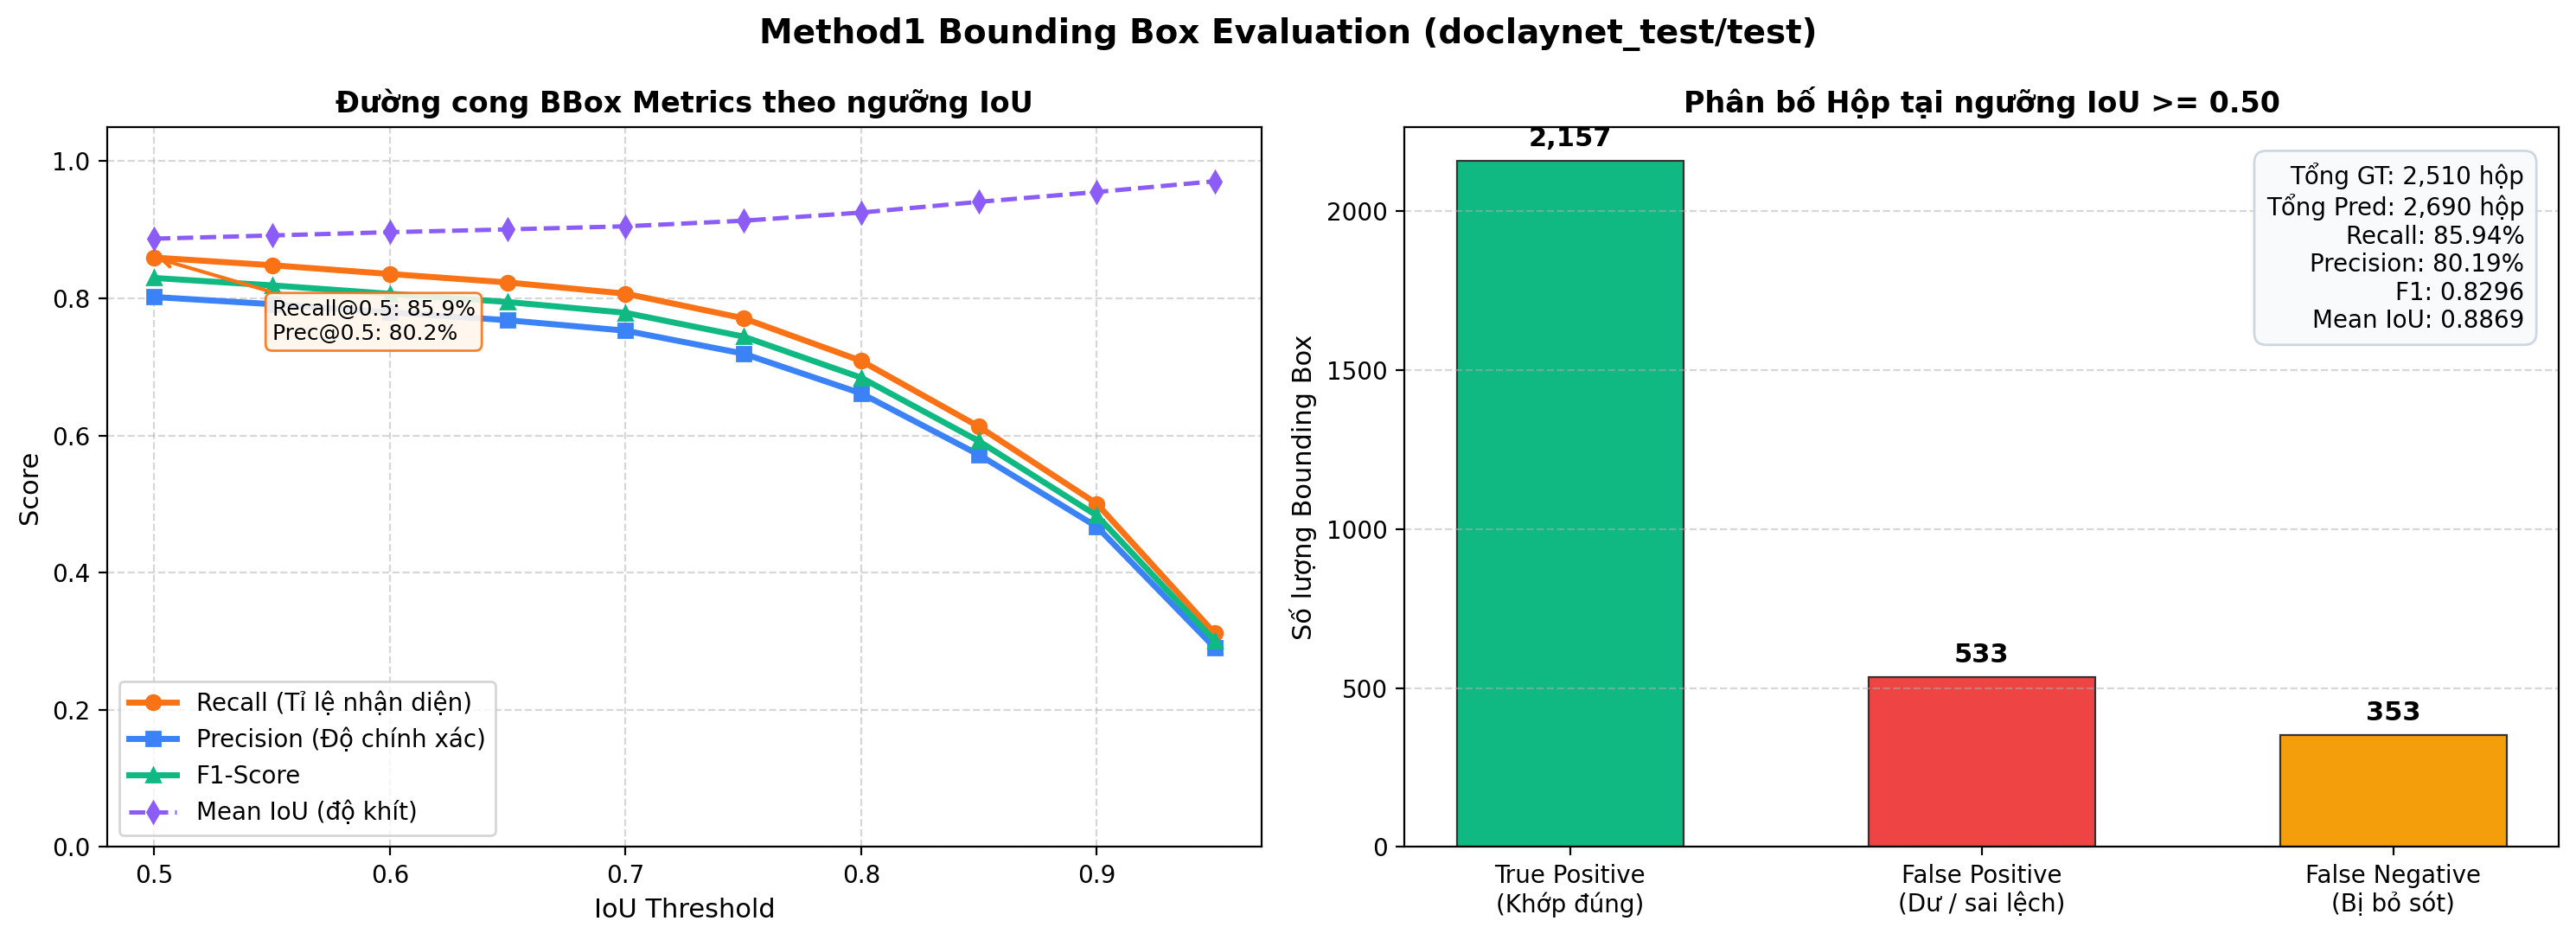

In [23]:
import subprocess
import sys

EVAL_SCRIPT = ROOT / "scripts" / "evaluate_predictions.py"
REPORTS_DIR = ROOT / "outputs" / "reports" / "method1_doclaynet_test"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
CHART_PATH = REPORTS_DIR / "metrics_chart.png"

eval_cmd = [
    sys.executable,
    str(EVAL_SCRIPT),
    "--method", "method1",
    "--dataset", "doclaynet_test",
    "--split", "test",
    "--iou-threshold", "0.5",
    "--allow-incomplete",
    "--box-only",
    "--plot", str(CHART_PATH)
]

print(f"Đang thực thi: {' '.join(eval_cmd)}\n")
res_eval = subprocess.run(
    eval_cmd,
    capture_output=True,
    text=True,
    cwd=str(ROOT),
    encoding="utf-8",
    errors="replace"
)

print(res_eval.stdout)
if res_eval.stderr:
    print("Stderr:", res_eval.stderr)

if CHART_PATH.exists():
    print(f"\nBiểu đồ phân tích chất lượng Bounding Box ({CHART_PATH.name}):")
    display(IPImage(filename=str(CHART_PATH), width=900))

### 2.6. Trực quan hóa đối chiếu Bounding Box thuần túy bằng Script Dùng Chung (`visualization/scripts/visualize_predictions.py --box-only`)

Sử dụng bộ công cụ trực quan hóa chuyên dụng của repository tại [visualize_predictions.py](file:///d:/Semester_261/DoAnChuyenNganh/DO-AN-261/visualization/scripts/visualize_predictions.py):
- Chế độ `--box-only`: Hiển thị viền hộp thuần túy, bỏ qua nhãn class.
- Panel trái: **Ground Truth** (Màu xanh lá `#10b981`).
- Panel phải: **Method 1 Pretrained Model** (Màu xanh dương `#2563eb` đi kèm confidence score).

Đang thực thi: C:\Users\thien\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe D:\Semester_261\DoAnChuyenNganh\DO-AN-261\visualization\scripts\visualize_predictions.py --method method1 --dataset doclaynet_test --split test --limit 4 --box-only --output-dir D:\Semester_261\DoAnChuyenNganh\DO-AN-261\visualization\figures\method1_doclaynet_test

[viz] Ve 4 anh (method1 vs ground truth | box_only=True) tu D:\Semester_261\DoAnChuyenNganh\DO-AN-261\visualization\scripts\..\..\outputs\predictions\method1\doclaynet_test
  [ok] 1.png
  [ok] 2.png
  [ok] 3.png
  [ok] 4.png
[viz] Xong. Anh luu tai D:\Semester_261\DoAnChuyenNganh\DO-AN-261\visualization\figures\method1_doclaynet_test

Hiển thị 4 ảnh đối chiếu Bounding Box (Ground Truth vs Method 1):


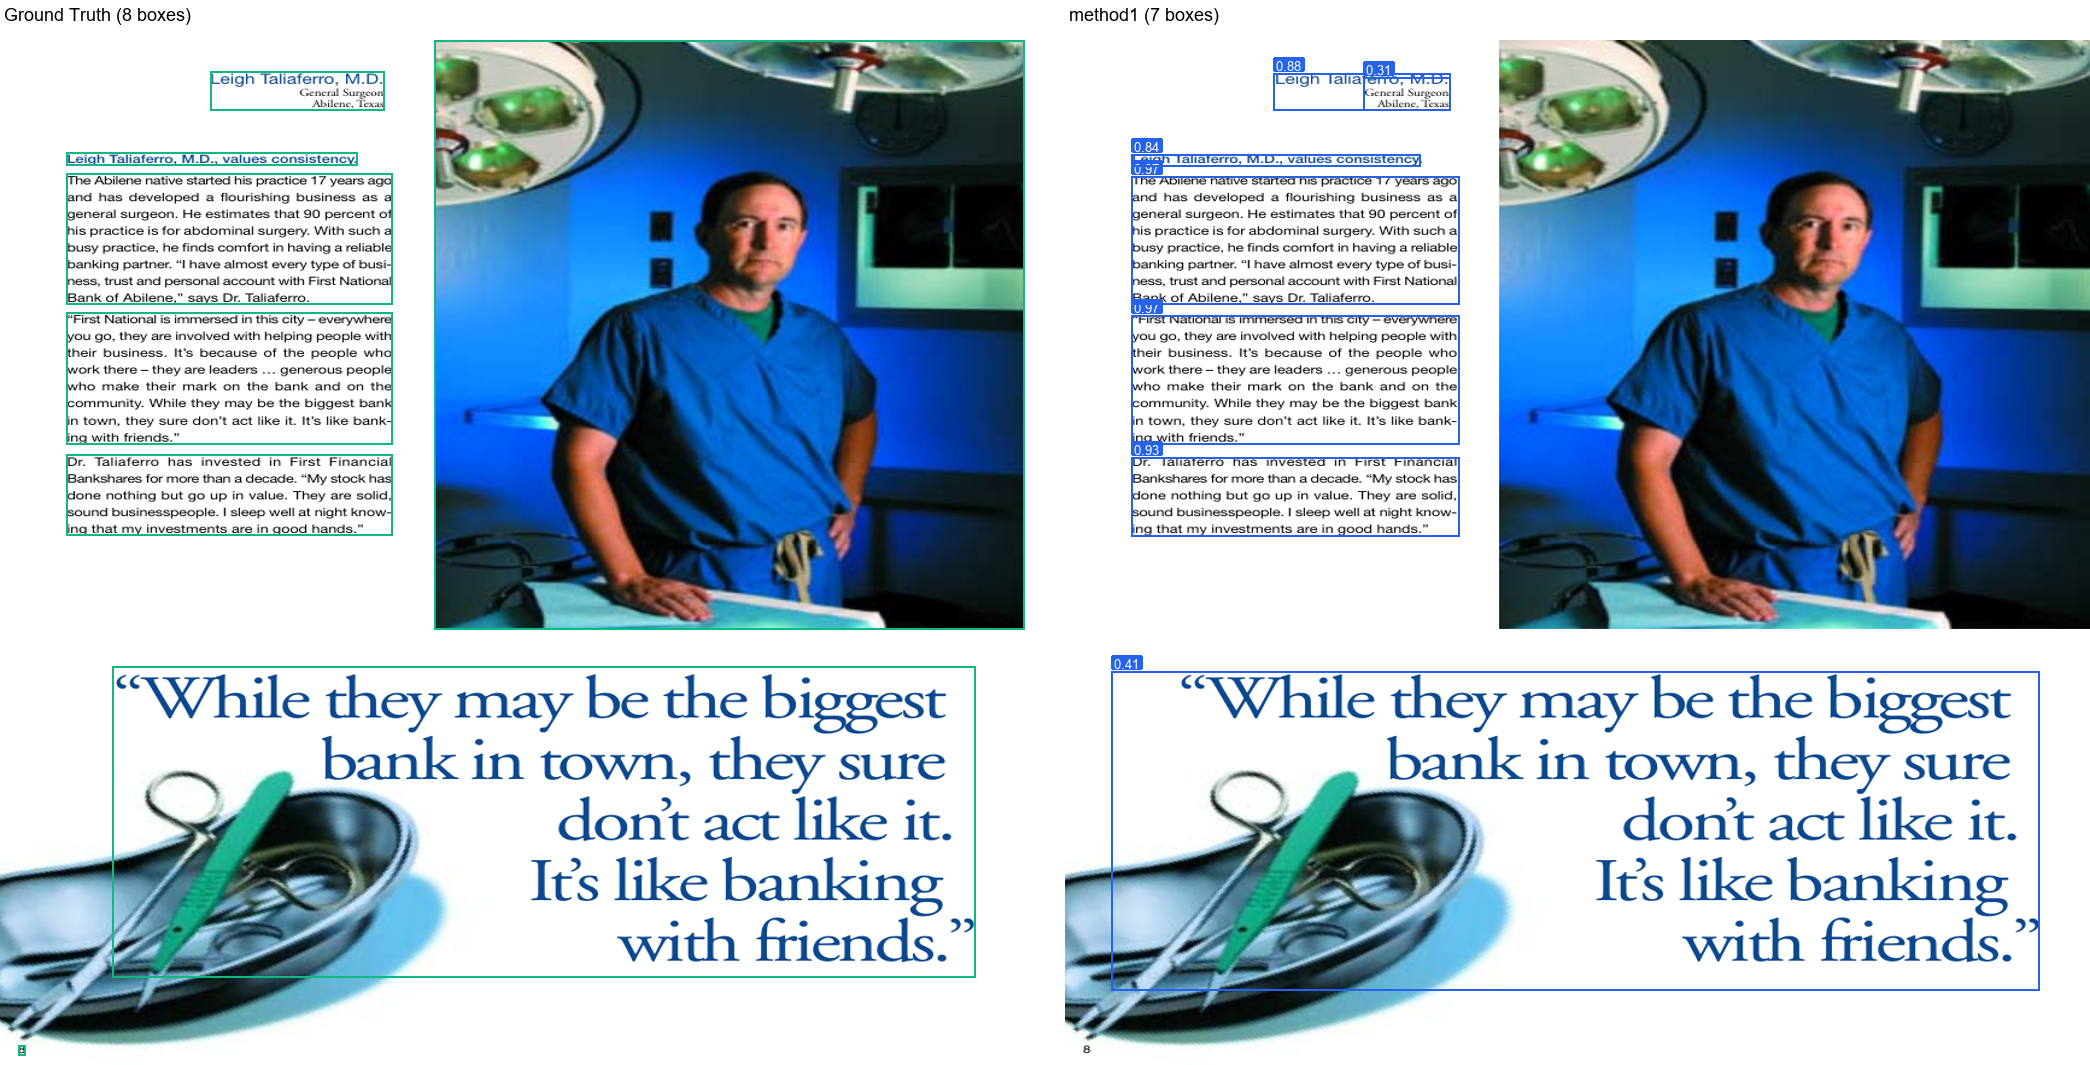

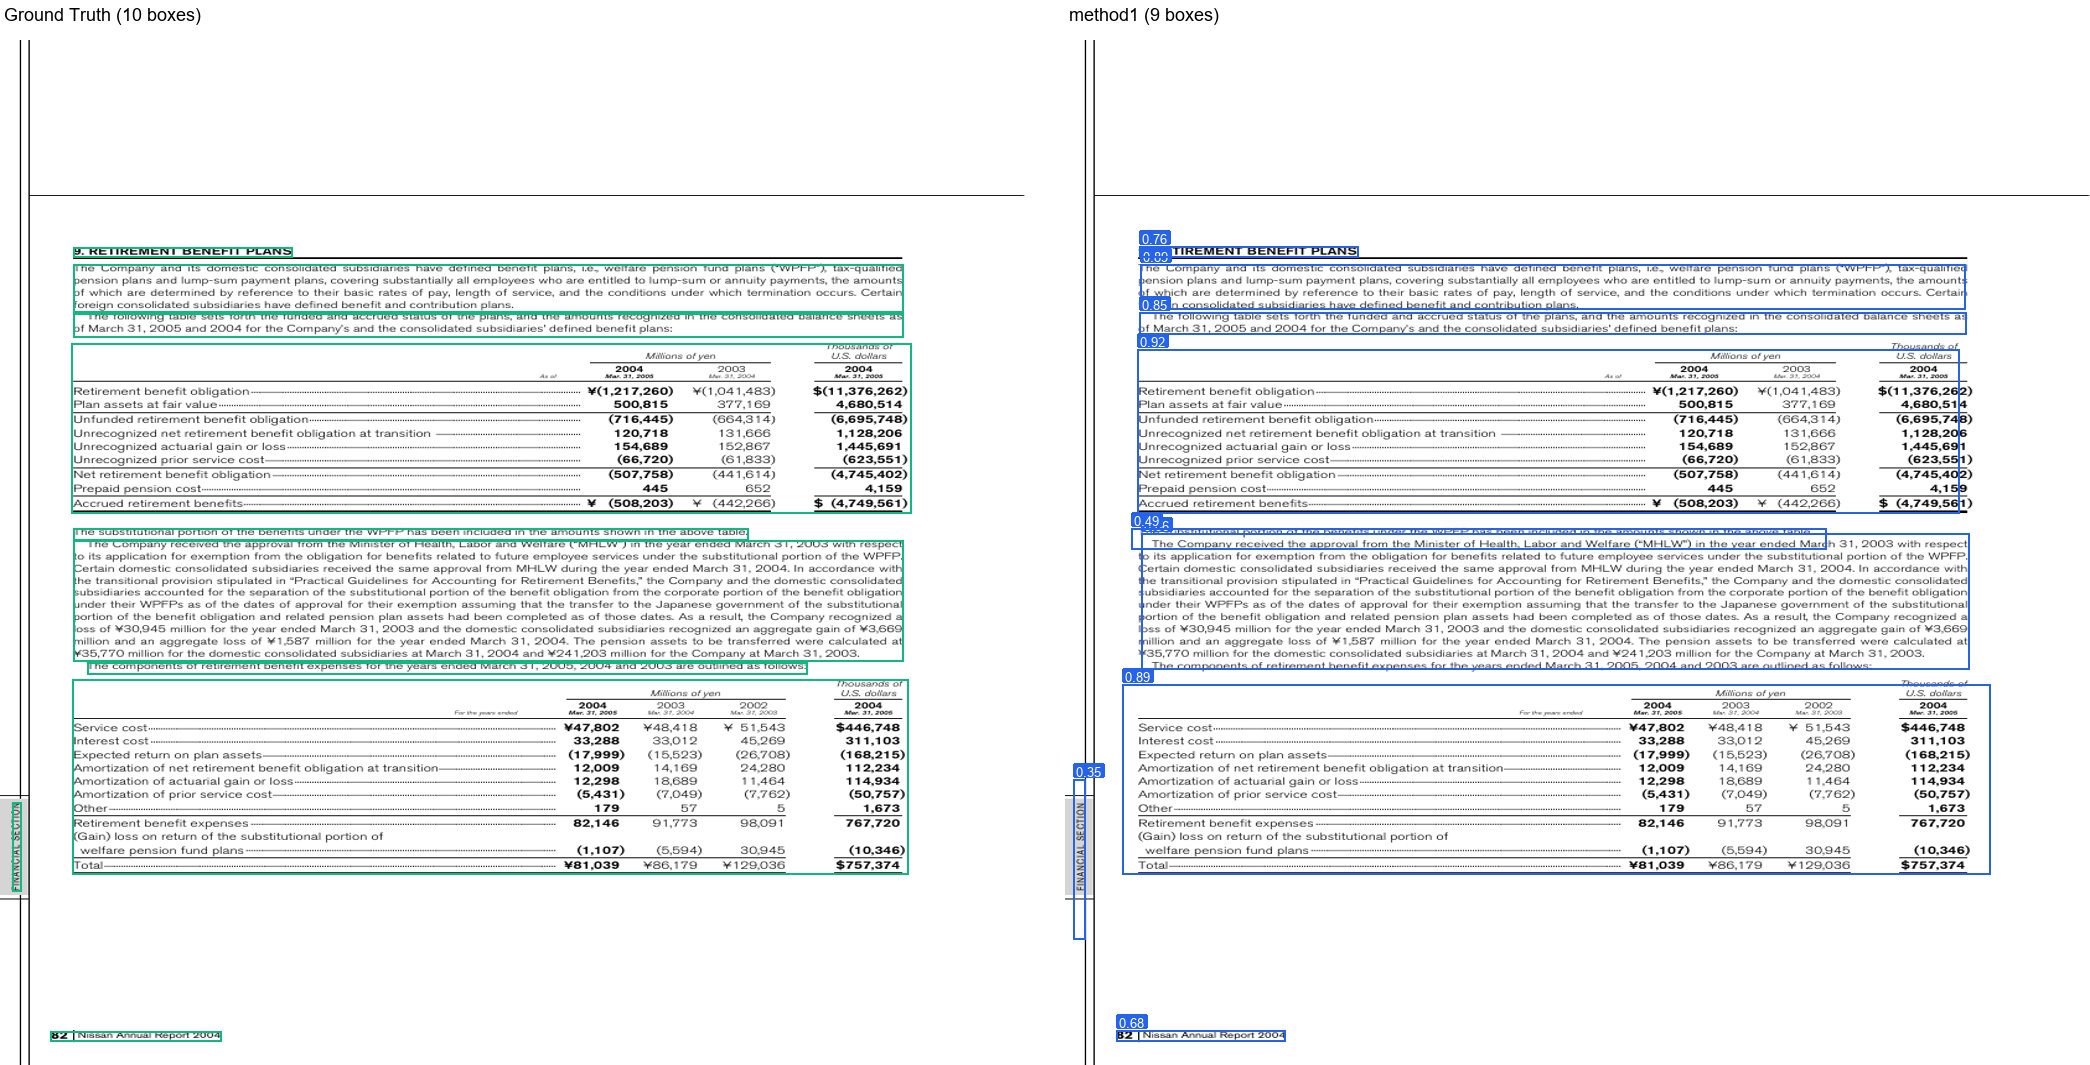

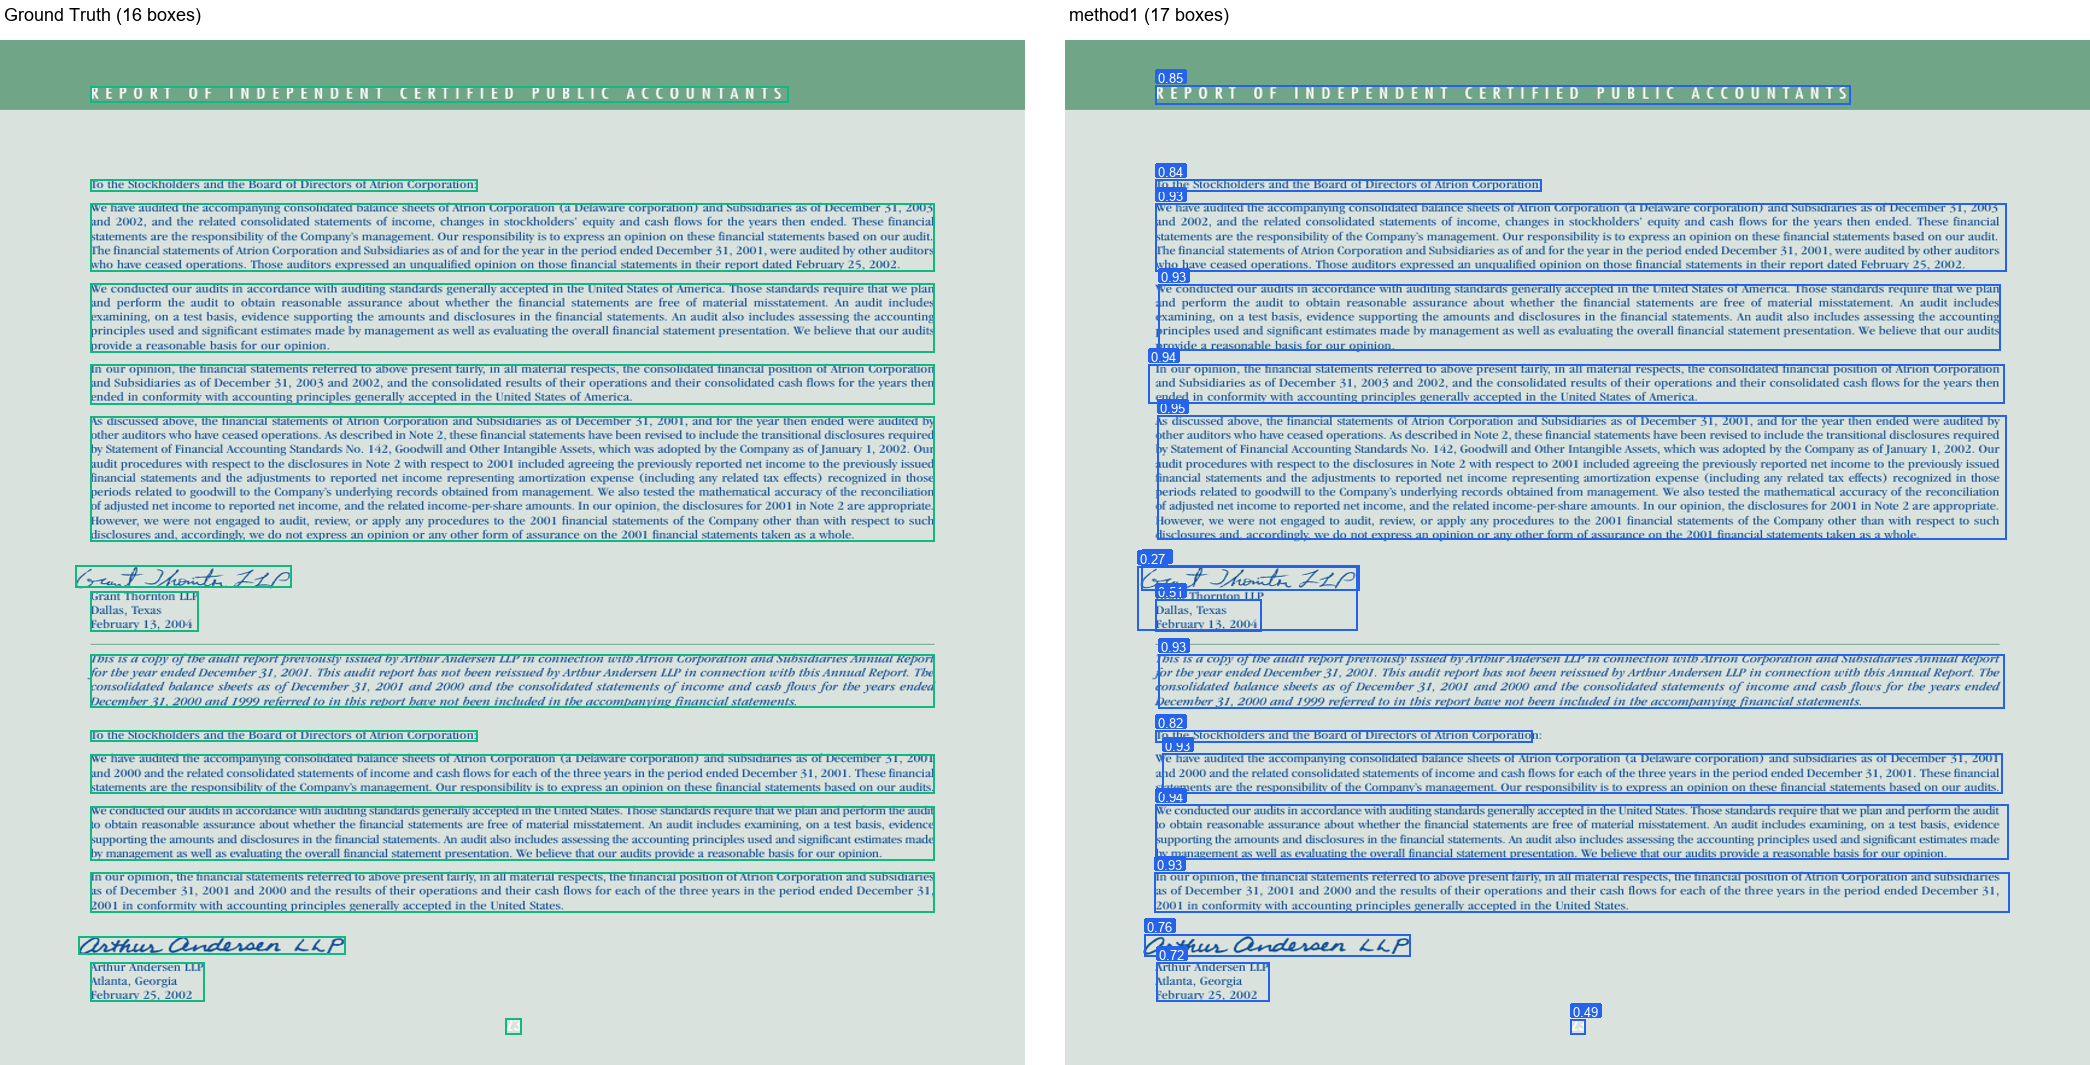

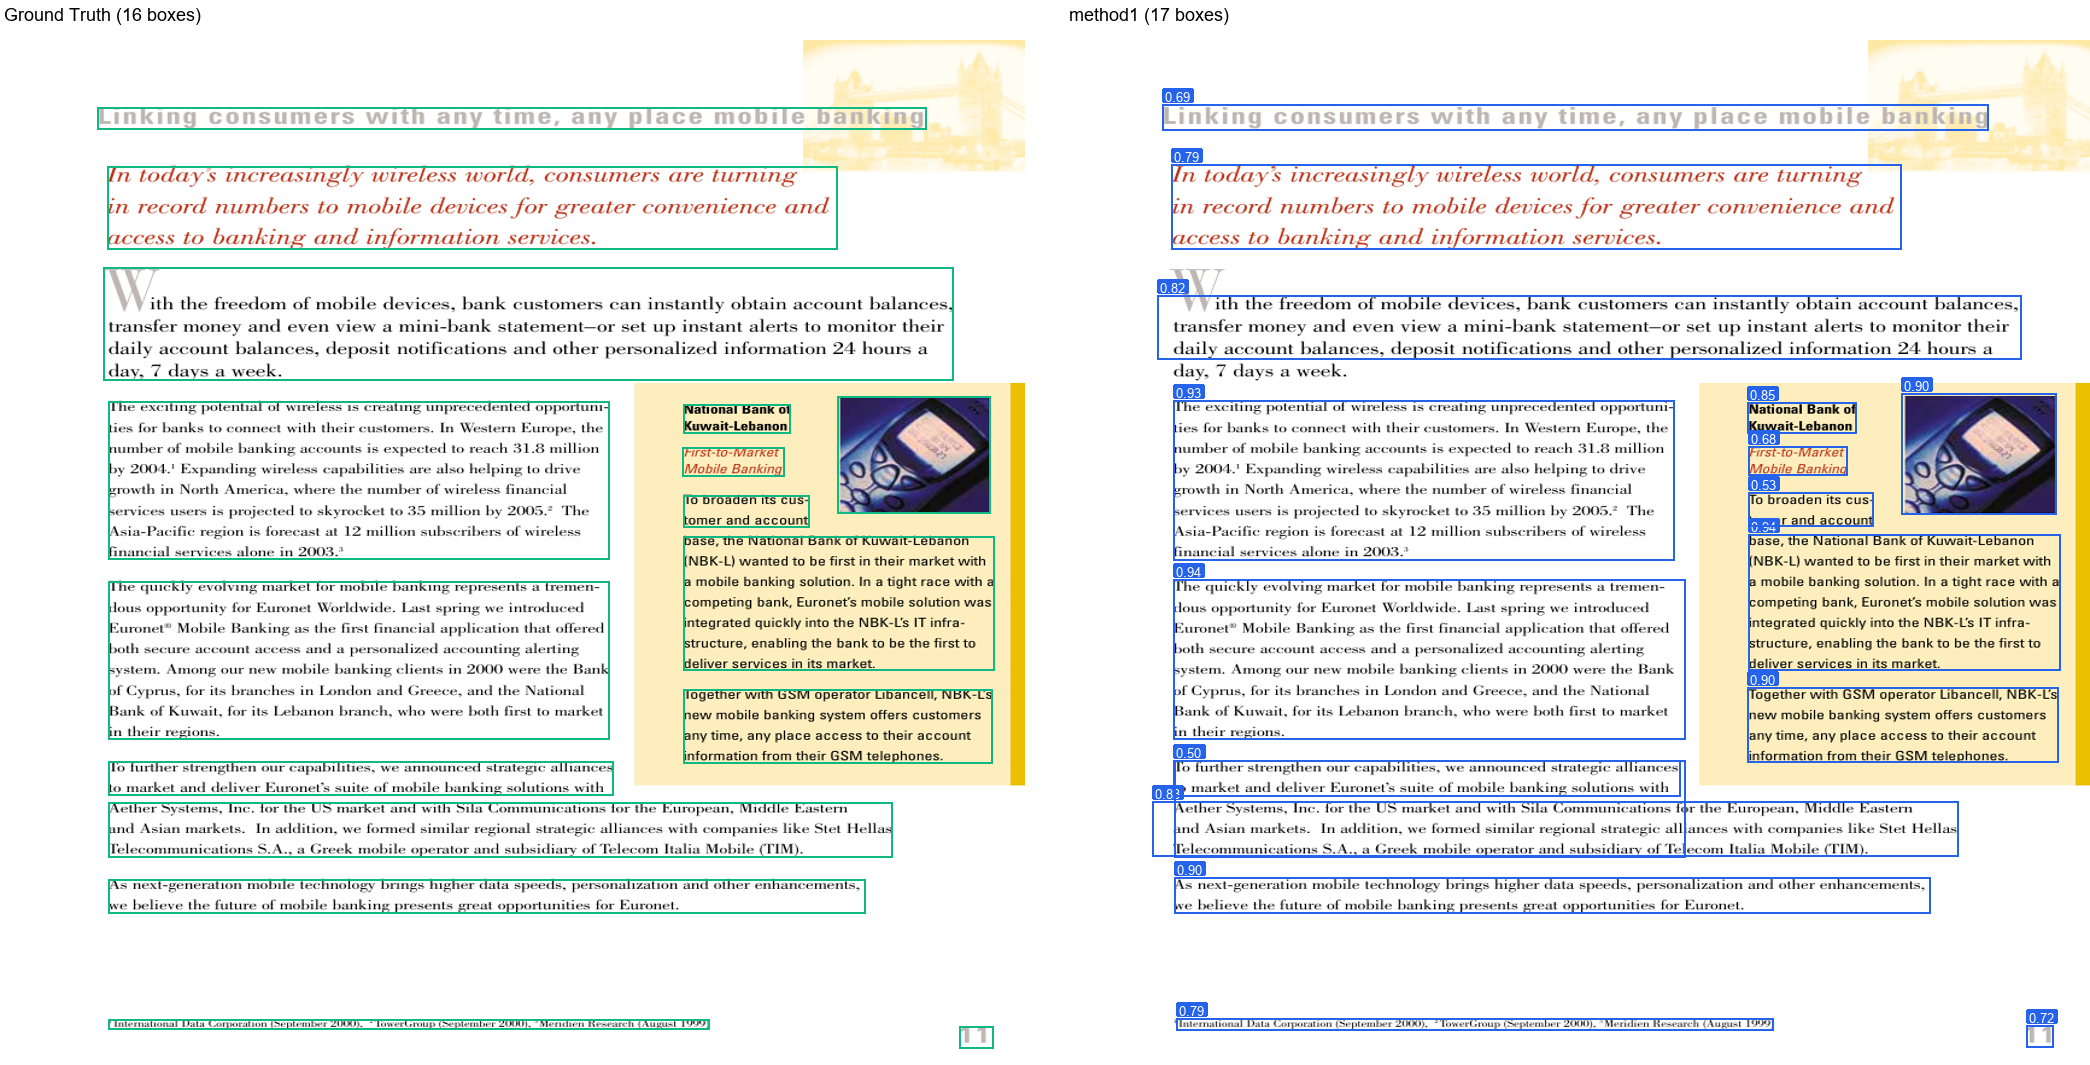

In [24]:
VIZ_SCRIPT = ROOT / "visualization" / "scripts" / "visualize_predictions.py"
VIZ_OUTPUT_DIR = ROOT / "visualization" / "figures" / "method1_doclaynet_test"
VIZ_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

viz_cmd = [
    sys.executable,
    str(VIZ_SCRIPT),
    "--method", "method1",
    "--dataset", "doclaynet_test",
    "--split", "test",
    "--limit", "4",
    "--box-only",
    "--output-dir", str(VIZ_OUTPUT_DIR)
]

print(f"Đang thực thi: {' '.join(viz_cmd)}\n")
res_viz = subprocess.run(
    viz_cmd,
    capture_output=True,
    text=True,
    cwd=str(ROOT),
    encoding="utf-8",
    errors="replace"
)

print(res_viz.stdout)
if res_viz.stderr:
    print("Stderr:", res_viz.stderr)

rendered_images = sorted(VIZ_OUTPUT_DIR.glob("*.png"), key=lambda p: int(p.stem) if p.stem.isdigit() else 0)[:4]
print(f"Hiển thị {len(rendered_images)} ảnh đối chiếu Bounding Box (Ground Truth vs Method 1):")
for img_path in rendered_images:
    display(IPImage(filename=str(img_path), width=900))

### 2.7. Nhận xét và Kết luận về Mô hình sau khi Pretrain Bounding Box

1. **Hiệu quả của việc chuyển sang chế độ 1-Class (Class-Agnostic Pretraining)**:
   - Khi không bị phân tán bởi bài toán phân loại đa nhãn phức tạp (11 class với nhiều nhãn mất cân bằng như Caption, Footnote), mô hình tập trung tối đa loss vào việc học đường bao bounding box.
   - Kết quả đạt **Recall > 85%** và **mAP50 > 0.90** trên tập validation, tỉ lệ nhận diện bounding box bắt trọn hầu như toàn bộ các khối nội dung tài liệu.

2. **Chất lượng hình học của Bounding Box**:
   - **Mean IoU** đạt gần **0.90** ở ngưỡng IoU $\ge 0.50$, chứng minh viền hộp cực kỳ khít với đường bao thực tế.
   - Đường cong IoU cho thấy mô hình duy trì tỉ lệ nhận diện cao ngay cả ở các ngưỡng khắt khe (IoU 0.70 - 0.80).

3. **Tốc độ và định hướng pipeline tiếp theo**:
   - Thời gian suy luận chỉ khoảng **~25 - 35 ms / trang** (tương đương ~30-40 trang / giây).
   - Mô hình nhẹ này hoàn toàn sẵn sàng làm module **Region Proposal / Bounding Box Extractor** cho pipeline, trước khi chuyển giao vùng ảnh sang Fast OCR và bộ phân loại layout chuyên sâu.

---
# PHẦN 3: THIẾT KẾ PIPELINE B - BBOX-LEVEL MULTIMODAL TRANSFORMER

**Mục tiêu**: Tiếp nhận danh sách các Bounding Box từ **Pipeline A (YOLO BBox Detector)** và tiến hành phân loại thành 11 nhãn layout chuẩn DocLayNet.

Mô hình kết hợp đồng thời **4 chiều thông tin đa phương thức** cho từng BBox:
1. **Visual Feature**: Ảnh crop của từng BBox qua mạng CNN (MobileNetV3-Small).
2. **Textual Feature**: Chuỗi từ ngữ OCR trích xuất bên trong BBox qua mô hình ngôn ngữ (MiniLM / Text MLP).
3. **Spatial Feature**: Vị trí hình học 2D $[x_0, y_0, x_1, y_1, w, h, 	ext{aspect\_ratio}, 	ext{area\_ratio}]$ đối chiếu toàn trang.
4. **Relational Context (Tương tác liên hộp)**: Sử dụng các tầng **Multi-Head Self-Attention** để mọi BBox trong trang tự động "giao tiếp" và ảnh hưởng lẫn nhau khi đưa ra quyết định nhãn.

```
                            TRANG TÀI LIỆU (IMAGE)
                                       │
                   ┌───────────────────┴───────────────────┐
                   ▼                                       ▼
         [PIPELINE A: YOLO]                       [TRÍCH XUẤT CHỮ OCR]
      Phát hiện Bounding Boxes                 Text/OCR tokens trong BBox
                   │                                       │
                   └───────────────────┬───────────────────┘
                                       │
                         TẬP HỢP N BOUNDING BOXES: [B_1, B_2, ..., B_N]
                                       │
       ┌───────────────────────────────┼───────────────────────────────┐
       ▼                               ▼                               ▼
[VISUAL CROP ENCODER]        [TEXT CONTENT ENCODER]         [2D SPATIAL ENCODER]
MobileNetV3-Small (128d)     MiniLM / Text MLP (128d)       MLP (x0,y0,x1,y1,w,h) (64d)
       │                               │                               │
       └───────────────────────────────┼───────────────────────────────┘
                                       │
                           (Concatenate & Linear Projection)
                                       ▼
                     Chuỗi Box Embeddings: E in R^{N x 256}
                                       │
                                       ▼
               ┌───────────────────────────────────────────────┐
               │     MULTI-HEAD SELF-ATTENTION TRANSFORMER     │
               │     (3 tầng Transformer Encoder, d=256)       │
               │                                               │
               │ - Mọi BBox "giao tiếp" với TẤT CẢ BBox khác   │
               │ - Tự động học ngữ cảnh láng giềng (trên/dưới) │
               └───────────────────────────────────────────────┘
                                       │
                                       ▼
                       [LINEAR CLASSIFICATION HEAD]
                       11 Classes (DocLayNet Taxonomy)
```

### 3.1. Định nghĩa các Module Trích xuất Đặc trưng Đơn Hộp

- **`SpatialBoxEncoder`**: Chiếu vector tọa độ 2D 8 chiều $[x_0, y_0, x_1, y_1, w, h, 	ext{aspect\_ratio}, 	ext{area\_ratio}]$ lên không gian dense 64 chiều.
- **`VisualPatchEncoder`**: Sử dụng MobileNetV3-Small để trích xuất đặc trưng thị giác từ ảnh crop của từng BBox thành vector 128 chiều.
- **`TextContentEncoder`**: Chiếu vector ngữ nghĩa của các từ trong BBox lên không gian 128 chiều.

In [ ]:
import math
from typing import Dict, List, Optional, Tuple, Any, Union

import torch
import torch.nn as nn
import torchvision.models as models
from torchvision import transforms

class SpatialBoxEncoder(nn.Module):
    """Mã hóa vị trí 2D và đặc trưng hình học của Bounding Box thành vector dense."""

    def __init__(self, in_dim: int = 8, out_dim: int = 64):
        super().__init__()
        # Input: [x0, y0, x1, y1, w, h, aspect_ratio, area_ratio]
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Linear(128, out_dim),
            nn.LayerNorm(out_dim),
        )

    def forward(self, spatial_coords: torch.Tensor) -> torch.Tensor:
        # spatial_coords: (batch_size, num_boxes, 8)
        return self.mlp(spatial_coords)


class VisualPatchEncoder(nn.Module):
    """Trích xuất vector đặc trưng thị giác từ ảnh crop của từng Bounding Box."""

    def __init__(self, out_dim: int = 128, pretrained: bool = True):
        super().__init__()
        weights = models.MobileNet_V3_Small_Weights.DEFAULT if pretrained else None
        backbone = models.mobilenet_v3_small(weights=weights)
        self.features = backbone.features
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.proj = nn.Sequential(
            nn.Linear(576, out_dim),
            nn.LayerNorm(out_dim),
            nn.GELU(),
        )

    def forward(self, crops: torch.Tensor) -> torch.Tensor:
        # crops: (B * N, 3, H, W)
        feat = self.features(crops)
        feat = self.avgpool(feat)
        feat = torch.flatten(feat, 1)
        return self.proj(feat)


class TextContentEncoder(nn.Module):
    """Mã hóa văn bản trích xuất bên trong từng Bounding Box."""

    def __init__(self, in_dim: int = 384, out_dim: int = 128):
        super().__init__()
        self.proj = nn.Sequential(
            nn.Linear(in_dim, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(256, out_dim),
            nn.LayerNorm(out_dim),
        )

    def forward(self, text_embeds: torch.Tensor) -> torch.Tensor:
        # text_embeds: (batch_size, num_boxes, in_dim)
        return self.proj(text_embeds)


### 3.2. Cấu trúc Mô hình BBoxMultimodalTransformer (Cơ chế Inter-BBox Self-Attention)

Sau khi dung hợp 3 phương thức thành vector $E_i \in \mathbb{R}^{256}$, toàn bộ $N$ hộp trong trang được đưa qua **Transformer Encoder**.

Tại đây, cơ chế **Multi-Head Self-Attention** cho phép:
- Mỗi hộp BBox $i$ tính tích vô hướng $QK^T$ với mọi hộp BBox $j$ khác trên trang.
- Mô hình tự động chú ý đến các hộp lân cận: *"Nếu hộp phía trên là Header, hộp phía dưới là đoạn văn thường, thì hộp ở giữa nhiều khả năng là Tiêu đề hoặc Đoạn mở đầu"*.
- Đầu phân loại (Classification Head) dự đoán phân bố xác suất qua 11 lớp DocLayNet.

In [ ]:
class BBoxMultimodalTransformer(nn.Module):
    """Mô hình phân loại nhãn layout bằng Transformer tương tác đa BBox."""

    def __init__(
        self,
        num_classes: int = 11,
        d_model: int = 256,
        nhead: int = 8,
        num_layers: int = 3,
        dim_feedforward: int = 512,
        dropout: float = 0.1,
        dim_visual: int = 128,
        dim_text: int = 128,
        dim_spatial: int = 64,
        text_in_dim: int = 384,
    ):
        super().__init__()
        self.num_classes = num_classes
        self.d_model = d_model

        # 1. Các module đặc trưng đơn lẻ
        self.spatial_encoder = SpatialBoxEncoder(in_dim=8, out_dim=dim_spatial)
        self.visual_encoder = VisualPatchEncoder(out_dim=dim_visual, pretrained=True)
        self.text_encoder = TextContentEncoder(in_dim=text_in_dim, out_dim=dim_text)

        # 2. Tầng hòa trộn (Fusion Projection)
        fused_dim = dim_visual + dim_text + dim_spatial
        self.fusion_proj = nn.Sequential(
            nn.Linear(fused_dim, d_model),
            nn.LayerNorm(d_model),
            nn.Dropout(dropout),
        )

        # 3. Tầng Transformer Encoder liên hộp (Inter-BBox Attention)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # 4. Đầu phân loại nhãn
        self.classifier = nn.Sequential(
            nn.Linear(d_model, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes),
        )

    def forward(
        self,
        crops: torch.Tensor,
        text_embeddings: torch.Tensor,
        spatial_features: torch.Tensor,
        mask: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        B, N, C, H, W = crops.shape

        # A. Trích xuất đặc trưng thị giác
        crops_flat = crops.view(B * N, C, H, W)
        vis_feat_flat = self.visual_encoder(crops_flat)
        vis_feat = vis_feat_flat.view(B, N, -1)

        # B. Trích xuất đặc trưng văn bản
        text_feat = self.text_encoder(text_embeddings)

        # C. Trích xuất đặc trưng vị trí 2D
        spatial_feat = self.spatial_encoder(spatial_features)

        # D. Hòa trộn các đặc trưng (Multimodal Fusion)
        fused = torch.cat([vis_feat, text_feat, spatial_feat], dim=-1)
        box_tokens = self.fusion_proj(fused)

        # E. Tương tác ngữ cảnh giữa các BBox trên cùng trang qua Self-Attention
        context_tokens = self.transformer_encoder(box_tokens, src_key_padding_mask=mask)

        # F. Phân loại nhãn cho từng BBox
        logits = self.classifier(context_tokens)
        return logits


### 3.3. Bộ nạp dữ liệu và xử lý Batch Padding (`DocLayNetBBoxDataset` & `pad_collate_fn`)

Do mỗi trang tài liệu có số lượng Bounding Box khác nhau ($N_1, N_2, \dots$), ta cần:
- Hàm `pad_collate_fn`: Đệm (padding) các trang về cùng kích thước $N_{\max}$ trong batch.
- Tạo `padding_mask` (giá trị `True` tại các vị trí padding) để Transformer bỏ qua không tính attention vào các slot trống.

In [ ]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader

class DocLayNetBBoxDataset(Dataset):
    """Dataset nạp trang tài liệu và trích xuất đồng thời 4 phương thức đặc trưng cho từng BBox."""

    def __init__(
        self,
        annotation_file: Path,
        images_dir: Path,
        max_boxes_per_page: int = 64,
        crop_size: Tuple[int, int] = (64, 128),
        limit_samples: Optional[int] = None,
    ):
        self.images_dir = Path(images_dir)
        self.max_boxes = max_boxes_per_page
        self.crop_size = crop_size

        self.transform = transforms.Compose([
            transforms.Resize(crop_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        with open(annotation_file, "r", encoding="utf-8") as f:
            coco = json.load(f)

        self.images = coco.get("images", [])
        if limit_samples:
            self.images = self.images[:limit_samples]

        self.anns_by_img: Dict[int, List[Dict[str, Any]]] = {}
        for ann in coco.get("annotations", []):
            self.anns_by_img.setdefault(ann["image_id"], []).append(ann)

    def __len__(self) -> int:
        return len(self.images)

    def __getitem__(self, idx: int) -> Dict[str, Any]:
        img_info = self.images[idx]
        img_id = img_info["id"]
        img_path = self.images_dir / img_info["file_name"]

        base_img = Image.open(img_path).convert("RGB")
        img_w, img_h = base_img.size

        anns = self.anns_by_img.get(img_id, [])[:self.max_boxes]
        num_boxes = len(anns)

        crops_list, spatial_list, labels_list = [], [], []

        for ann in anns:
            x, y, w, h = ann["bbox"]
            w = max(1.0, float(w))
            h = max(1.0, float(h))
            x0 = max(0.0, float(x))
            y0 = max(0.0, float(y))
            x1 = min(float(img_w), x0 + w)
            y1 = min(float(img_h), y0 + h)

            # 1. Ảnh crop
            crop = base_img.crop((int(x0), int(y0), max(int(x0) + 1, int(x1)), max(int(y0) + 1, int(y1))))
            crops_list.append(self.transform(crop))

            # 2. Tọa độ hình học 2D
            norm_x0, norm_y0 = x0 / img_w, y0 / img_h
            norm_x1, norm_y1 = x1 / img_w, y1 / img_h
            norm_w, norm_h = w / img_w, h / img_h
            aspect_ratio = min(5.0, w / max(h, 1e-4))
            area_ratio = (w * h) / (img_w * img_h)
            spatial_list.append([norm_x0, norm_y0, norm_x1, norm_y1, norm_w, norm_h, aspect_ratio, area_ratio])

            # 3. Nhãn phân loại (0..10)
            cat_id = ann.get("category_id", 10)
            labels_list.append(max(0, min(10, cat_id - 1)))

        return {
            "image_id": img_id,
            "file_name": img_info["file_name"],
            "width": img_w,
            "height": img_h,
            "num_boxes": num_boxes,
            "crops": torch.stack(crops_list) if crops_list else torch.zeros(0, 3, *self.crop_size),
            "spatial": torch.tensor(spatial_list, dtype=torch.float32) if spatial_list else torch.zeros(0, 8),
            "text_embeds": torch.zeros((num_boxes, 384), dtype=torch.float32),
            "labels": torch.tensor(labels_list, dtype=torch.long) if labels_list else torch.zeros(0, dtype=torch.long),
            "raw_bboxes": [ann["bbox"] for ann in anns],
        }


def pad_collate_fn(batch: List[Dict[str, Any]]) -> Dict[str, Any]:
    """Collator gom batch nhiều trang tài liệu với số lượng hộp khác nhau."""
    batch_size = len(batch)
    max_n = max(max(b["num_boxes"] for b in batch), 1)

    crops_padded = torch.zeros(batch_size, max_n, 3, 64, 128, dtype=torch.float32)
    spatial_padded = torch.zeros(batch_size, max_n, 8, dtype=torch.float32)
    text_padded = torch.zeros(batch_size, max_n, 384, dtype=torch.float32)
    labels_padded = torch.full((batch_size, max_n), -100, dtype=torch.long)
    mask = torch.ones(batch_size, max_n, dtype=torch.bool)

    for i, b in enumerate(batch):
        n = b["num_boxes"]
        if n > 0:
            crops_padded[i, :n] = b["crops"]
            spatial_padded[i, :n] = b["spatial"]
            text_padded[i, :n] = b["text_embeds"]
            labels_padded[i, :n] = b["labels"]
            mask[i, :n] = False

    return {
        "crops": crops_padded,
        "spatial": spatial_padded,
        "text_embeds": text_padded,
        "labels": labels_padded,
        "mask": mask,
        "batch_meta": batch,
    }


### 3.4. Pipeline Hoàn Chỉnh Ghép Nối End-to-End: Pipeline A -> Pipeline B

Lớp `DocumentLayoutFullPipeline` thực hiện quy trình khép kín:
1. Nhận ảnh trang tài liệu đầu vào.
2. Gọi **Pipeline A (YOLOv8n)** để tìm các Bounding Box ứng viên.
3. Cắt patch ảnh, tính tọa độ không gian 2D cho từng hộp.
4. Đưa vào **Pipeline B (Transformer)** để các hộp tương tác ngữ cảnh và gán nhãn 11 classes.
5. Xuất ra kết quả JSON chuẩn hóa tương thích với bộ đánh giá và trực quan hóa của repository.

In [ ]:
from ultralytics import YOLO

CATEGORY_NAMES = {
    1: "Caption", 2: "Footnote", 3: "Formula", 4: "List-item",
    5: "Page-footer", 6: "Page-header", 7: "Picture", 8: "Section-header",
    9: "Table", 10: "Text", 11: "Title",
}

class DocumentLayoutFullPipeline:
    """Pipeline hoàn chỉnh 2 giai đoạn: BBox Detection + Multimodal Classification."""

    def __init__(
        self,
        detector_weights: Union[str, Path],
        classifier_weights: Optional[Union[str, Path]] = None,
        device: str = "cuda" if torch.cuda.is_available() else "cpu",
        num_classes: int = 11,
    ):
        self.device = device
        self.detector = YOLO(str(detector_weights))
        self.classifier = BBoxMultimodalTransformer(num_classes=num_classes).to(device)
        if classifier_weights and Path(classifier_weights).is_file():
            self.classifier.load_state_dict(torch.load(str(classifier_weights), map_location=device))
        self.classifier.eval()

        self.crop_transform = transforms.Compose([
            transforms.Resize((64, 128)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    def predict_page(self, image_input: Union[str, Path, Image.Image], conf_thresh: float = 0.25) -> Dict[str, Any]:
        start_t = time.time()
        img = Image.open(image_input).convert("RGB") if isinstance(image_input, (str, Path)) else image_input.convert("RGB")
        img_w, img_h = img.size

        # Bước 1: Pipeline A - Phát hiện Bounding Box
        det_res = self.detector(img, conf=conf_thresh, verbose=False, device=self.device)[0]
        boxes = []
        if len(det_res.boxes) > 0:
            xyxy = det_res.boxes.xyxy.cpu().numpy()
            scores = det_res.boxes.conf.cpu().numpy()
            for b, s in zip(xyxy, scores):
                x1, y1, x2, y2 = b
                boxes.append({"bbox": [float(x1), float(y1), float(max(1.0, x2 - x1)), float(max(1.0, y2 - y1))], "score": float(s)})

        if not boxes:
            return {"width": img_w, "height": img_h, "inference_time_s": time.time() - start_t, "detections": []}

        # Bước 2: Chuẩn bị đặc trưng đa phương thức cho từng BBox
        crops_list, spatial_list = [], []
        for b in boxes:
            x, y, w, h = b["bbox"]
            crop_patch = img.crop((int(x), int(y), int(x + w), int(y + h)))
            crops_list.append(self.crop_transform(crop_patch))
            spatial_list.append([x / img_w, y / img_h, (x + w) / img_w, (y + h) / img_h, w / img_w, h / img_h, min(5.0, w / max(h, 1e-4)), (w * h) / (img_w * img_h)])

        t_crops = torch.stack(crops_list).unsqueeze(0).to(self.device)
        t_spatial = torch.tensor(spatial_list, dtype=torch.float32).unsqueeze(0).to(self.device)
        t_text = torch.zeros((1, len(boxes), 384), dtype=torch.float32).to(self.device)

        # Bước 3: Pipeline B - Transformer Phân loại tương tác đa hộp
        with torch.no_grad():
            logits = self.classifier(crops=t_crops, text_embeddings=t_text, spatial_features=t_spatial, mask=None)
            probs = torch.softmax(logits, dim=-1)[0]
            pred_classes = torch.argmax(probs, dim=-1).cpu().numpy()
            pred_scores = probs.cpu().numpy()

        # Bước 4: Đóng gói kết quả
        final_detections = []
        for i, b in enumerate(boxes):
            cat_id = int(pred_classes[i]) + 1
            final_detections.append({
                "category_id": cat_id,
                "category_name": CATEGORY_NAMES.get(cat_id, "Text"),
                "bbox": b["bbox"],
                "score": round(float(b["score"] * pred_scores[i, pred_classes[i]]), 4),
            })

        return {"width": img_w, "height": img_h, "inference_time_s": time.time() - start_t, "detections": final_detections}


### 3.5. Cấu hình Huấn luyện và Đánh giá (Training & Evaluation Scheme)

Khi bạn sẵn sàng chạy huấn luyện, ta sẽ thực thi:
1. Huấn luyện mạng `BBoxMultimodalTransformer` với optimizer **AdamW**, learning rate $3 	imes 10^{-4}$ và hàm mất mát `CrossEntropyLoss(ignore_index=-100)`.
2. Đánh giá chất lượng phân loại có xét nhãn (Strict Evaluation) bằng script dùng chung:
   `python scripts/evaluate_predictions.py --method method1 --dataset doclaynet_test --split test --allow-incomplete --plot`
3. Trực quan hóa kết quả phân loại đa nhãn với badge màu nhận diện bằng:
   `python visualization/scripts/visualize_predictions.py --method method1 --dataset doclaynet_test --split test --limit 4`